In [1]:
!apt-get update -qq
!apt-get install -y poppler-utils

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  libpoppler-dev libpoppler-private-dev libpoppler134
The following NEW packages will be installed:
  poppler-utils
The following packages will be upgraded:
  libpoppler-dev libpoppler-private-dev libpoppler134
3 upgraded, 1 newly installed, 0 to remove and 91 not upgraded.
Need to get 1,532 kB of archives.
After this operation, 735 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 libpoppler-private-dev amd64 24.02.0-1ubuntu9.11 [197 kB]
Get:2 http://archive.ubuntu.com/ubuntu noble-updates/main amd64 libpoppler-dev amd64 24.02.0-1ubuntu9.11 [5,202 B]
Get:3 http://archive.ubuntu.com/ubuntu noble-up

In [2]:
!pip install -q pdf2image

from pdf2image import convert_from_path
import matplotlib.pyplot as plt
import numpy as np
import cv2
from pathlib import Path

In [3]:
pdf_files = list(Path("/kaggle/input").rglob("bilan_group_2.pdf"))

if not pdf_files:
    raise FileNotFoundError("PDF introuvable dans Kaggle Input")

pdf_path = str(pdf_files[0])

print("PDF trouvé :", pdf_path)

PDF trouvé : /kaggle/input/datasets/hamzaelattar911/bilan-extraction/bilan_group_2.pdf


Nombre de pages : 2
Page 1 : (5250, 3717, 3)


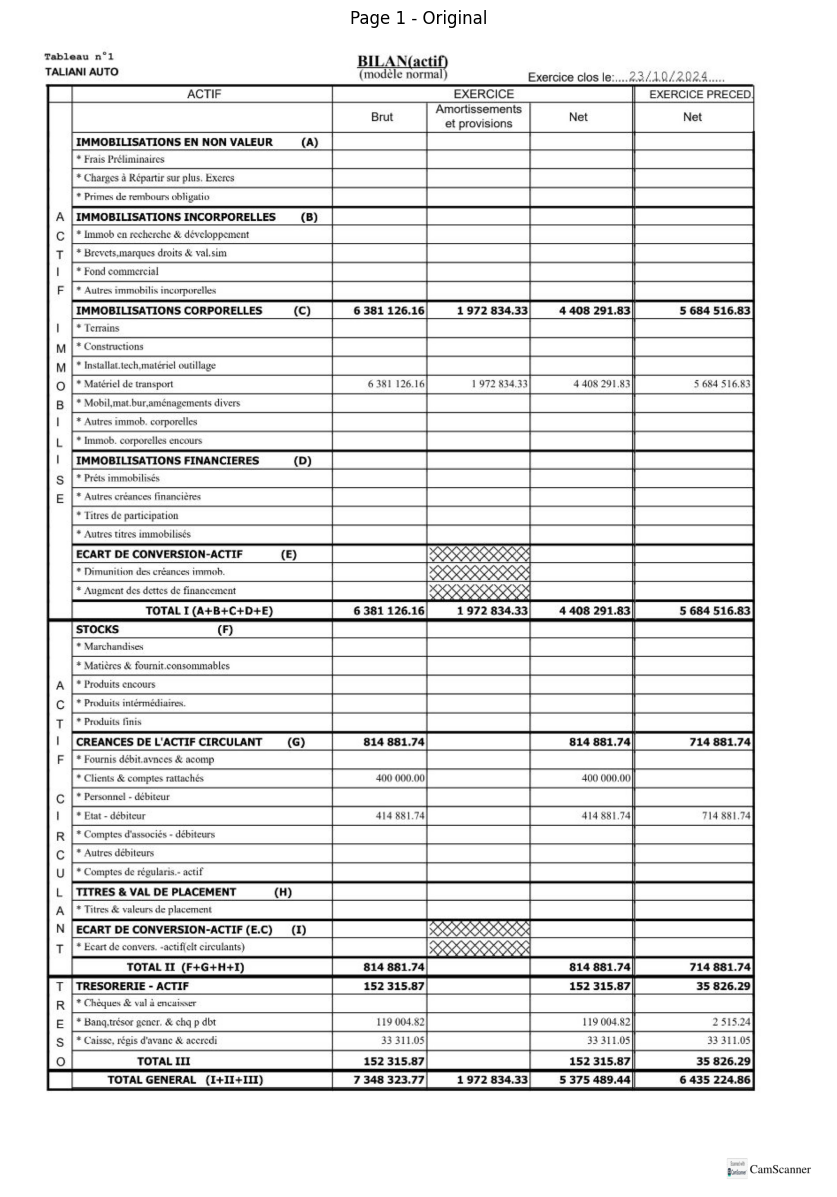

Page 2 : (5250, 3717, 3)


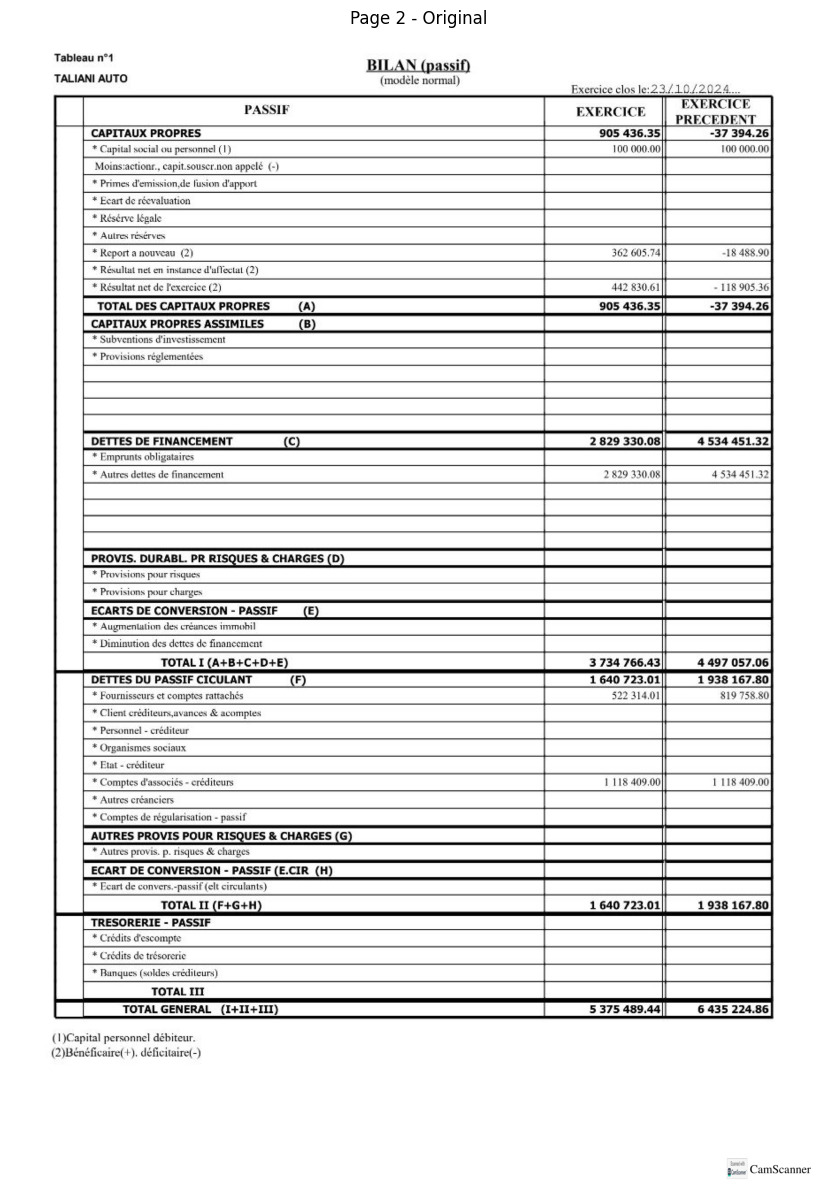

In [4]:
pages = convert_from_path(
    pdf_path,
    dpi=300
)

print("Nombre de pages :", len(pages))

for i, page in enumerate(pages):
    image = np.array(page)

    print(f"Page {i+1} : {image.shape}")

    plt.figure(figsize=(12, 15))
    plt.imshow(image)
    plt.title(f"Page {i+1} - Original")
    plt.axis("off")
    plt.show()

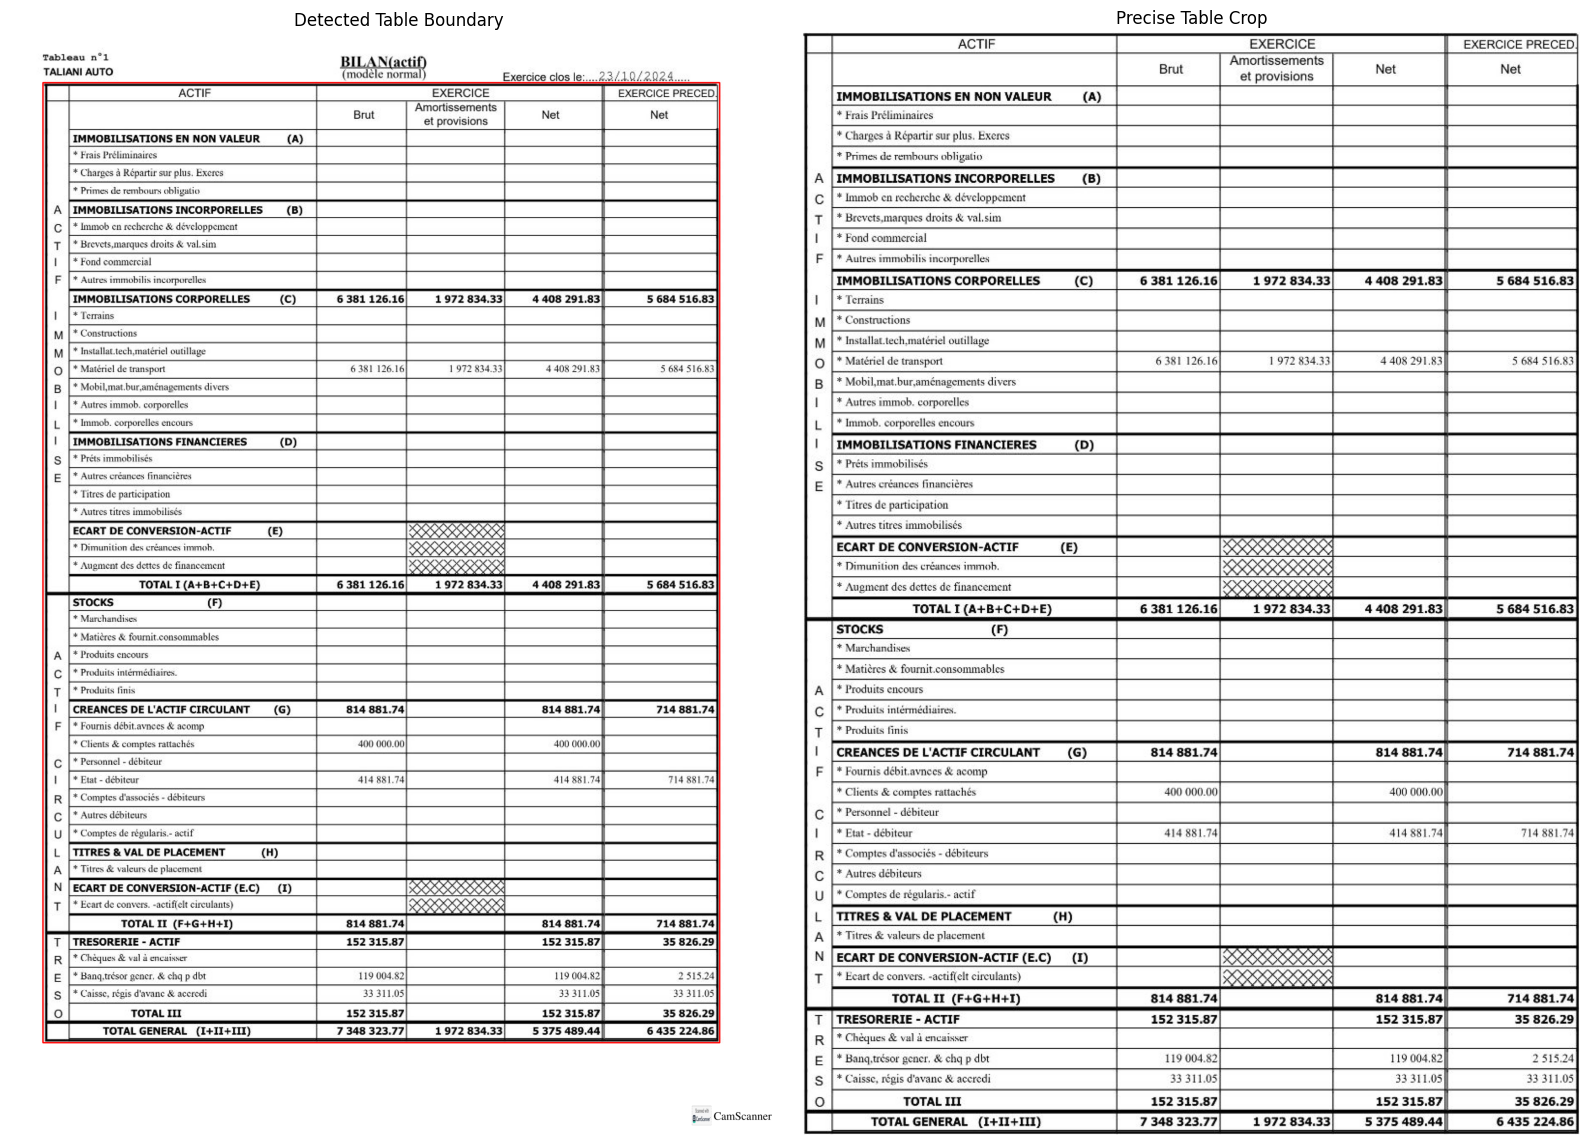

Original: (5250, 3717, 3)
Cropped: (4586, 3233, 3)


In [5]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Original image
image = np.array(pages[0].convert("RGB"))

gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Binary inversion
_, binary = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

h, w = binary.shape

# Detect horizontal lines
horizontal_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (max(40, w // 30), 1)
)

horizontal = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    horizontal_kernel
)

# Detect vertical lines
vertical_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (1, max(40, h // 30))
)

vertical = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    vertical_kernel
)

# Combine horizontal and vertical lines
table_mask = cv2.bitwise_or(horizontal, vertical)

# Connect nearby table structures
kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (7, 7)
)

connected = cv2.morphologyEx(
    table_mask,
    cv2.MORPH_CLOSE,
    kernel
)

# Find external contours
contours, _ = cv2.findContours(
    connected,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

# Select largest rectangular region
if not contours:
    raise ValueError("No table detected")

largest_contour = max(contours, key=cv2.contourArea)

x, y, bw, bh = cv2.boundingRect(largest_contour)

# Small padding
pad = 5

x1 = max(0, x - pad)
y1 = max(0, y - pad)
x2 = min(w, x + bw + pad)
y2 = min(h, y + bh + pad)

cropped = image[y1:y2, x1:x2]

# Visualization
preview = image.copy()

cv2.rectangle(
    preview,
    (x1, y1),
    (x2, y2),
    (255, 0, 0),
    5
)

fig, axes = plt.subplots(1, 2, figsize=(16, 12))

axes[0].imshow(preview)
axes[0].set_title("Detected Table Boundary")
axes[0].axis("off")

axes[1].imshow(cropped)
axes[1].set_title("Precise Table Crop")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Original:", image.shape)
print("Cropped:", cropped.shape)

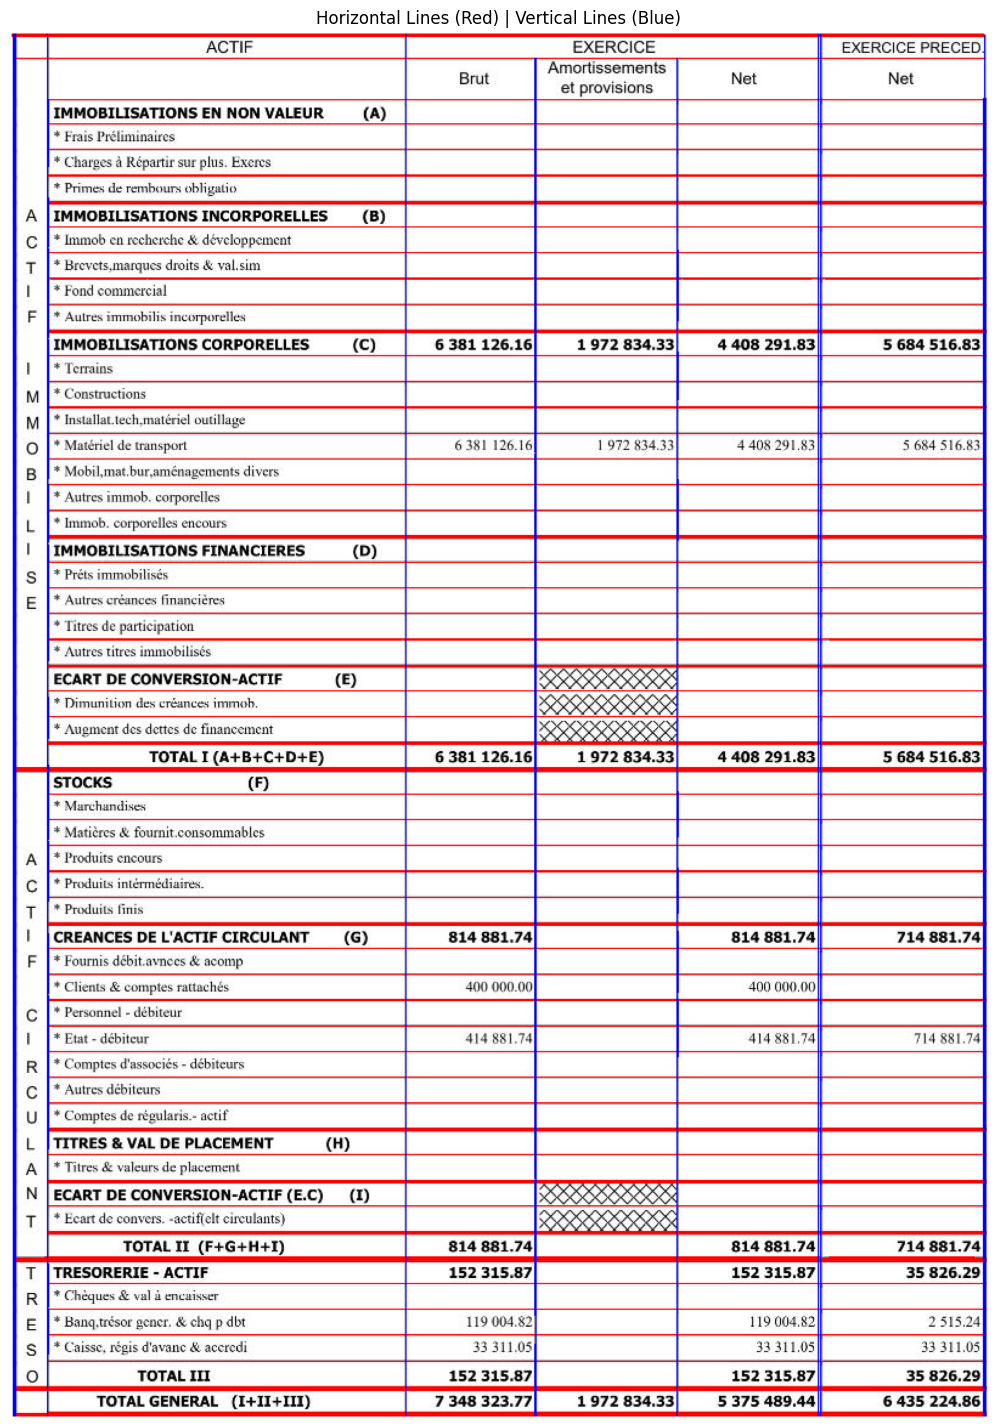

In [6]:
# Convert cropped image to grayscale
gray_crop = cv2.cvtColor(
    cropped, cv2.COLOR_RGB2GRAY
)

# Binary inversion
_, binary_crop = cv2.threshold(
    gray_crop, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

height, width = binary_crop.shape

# Detect horizontal lines
horizontal_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (max(30, width // 35), 1)
)

horizontal_lines = cv2.morphologyEx(
    binary_crop,
    cv2.MORPH_OPEN,
    horizontal_kernel
)

# Detect vertical lines
vertical_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (1, max(30, height // 35))
)

vertical_lines = cv2.morphologyEx(
    binary_crop,
    cv2.MORPH_OPEN,
    vertical_kernel
)

# Create colored overlay
overlay = cropped.copy()

overlay[horizontal_lines > 0] = [255, 0, 0]
overlay[vertical_lines > 0] = [0, 0, 255]

# Display result
plt.figure(figsize=(14, 18))
plt.imshow(overlay)
plt.title("Horizontal Lines (Red) | Vertical Lines (Blue)")
plt.axis("off")
plt.show()

In [7]:
import cv2
import numpy as np

# ====================================
# 1. DETECTION DES LIGNES
# ====================================

height, width = horizontal_lines.shape

projection = np.sum(horizontal_lines > 0, axis=1)

positions = np.where(
    projection > width * 0.35
)[0]

groups = np.split(
    positions,
    np.where(np.diff(positions) > 1)[0] + 1
)

row_boundaries = sorted([
    int(np.mean(group))
    for group in groups if len(group) > 0
])

rows_info = []

for y1, y2 in zip(
    row_boundaries[:-1],
    row_boundaries[1:]
):
    if y2 - y1 < 8:
        continue

    rows_info.append({
        "id_ligne": len(rows_info) + 1,
        "y1": int(y1),
        "y2": int(y2)
    })

print("Lignes détectées :", len(rows_info))


# ====================================
# 2. DETECTION DES COLONNES
# ====================================

projection_v = np.sum(
    vertical_lines > 0,
    axis=0
)

positions_v = np.where(
    projection_v > height * 0.35
)[0]

groups_v = np.split(
    positions_v,
    np.where(np.diff(positions_v) > 1)[0] + 1
)

column_boundaries = sorted([
    int(np.mean(group))
    for group in groups_v if len(group) > 0
])


# Fusion des lignes verticales proches
def merge_close_boundaries(boundaries, tolerance=15):

    boundaries = sorted(boundaries)

    if not boundaries:
        return []

    groups = [[boundaries[0]]]

    for x in boundaries[1:]:
        if x - groups[-1][-1] <= tolerance:
            groups[-1].append(x)
        else:
            groups.append([x])

    return [
        int(round(np.mean(group)))
        for group in groups
    ]


column_boundaries = merge_close_boundaries(
    column_boundaries,
    tolerance=15
)

print("Colonnes détectées :", column_boundaries)

assert len(rows_info) == 53, "Vérifier les lignes"
assert len(column_boundaries) == 7, "Vérifier les colonnes"

Lignes détectées : 53
Colonnes détectées : [14, 125, 1308, 1736, 2204, 2675, 3221]


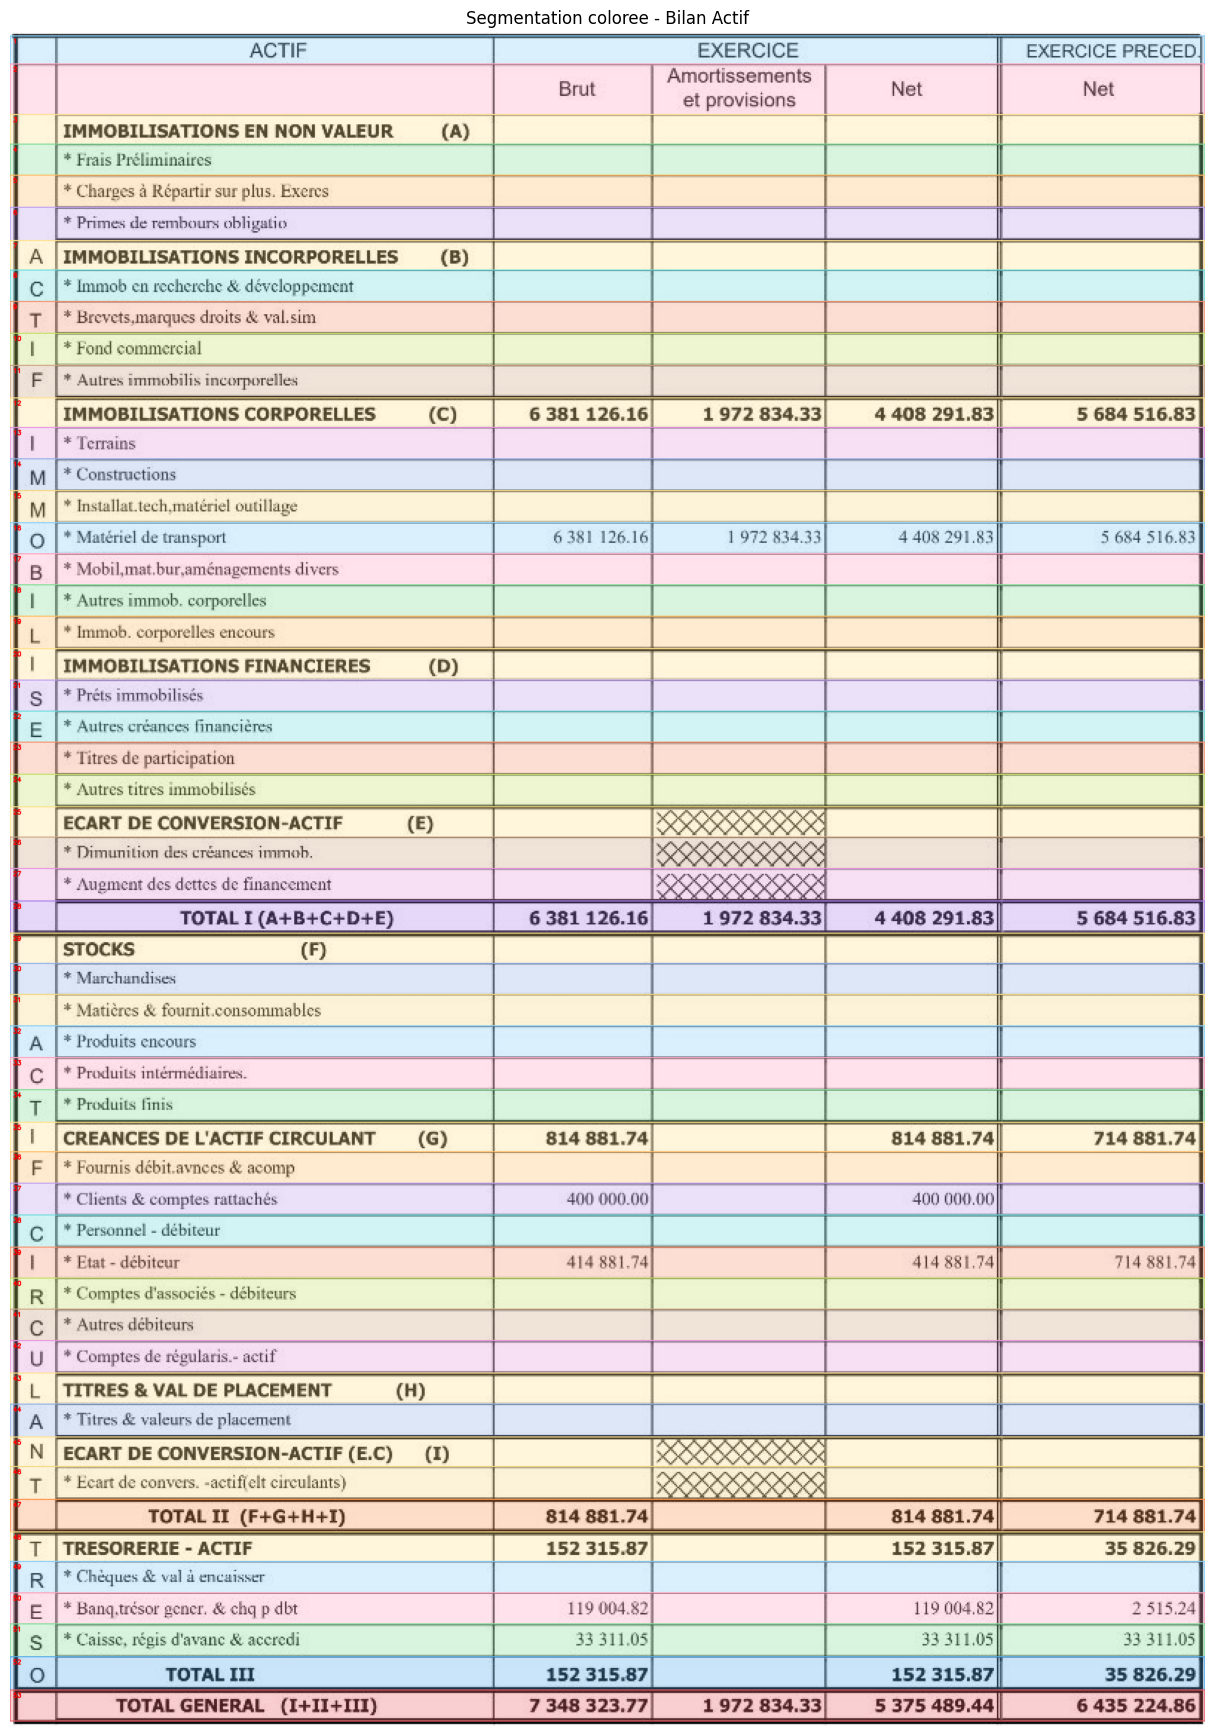

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

PALETTE = [
    (135, 206, 250),
    (255, 160, 190),
    (130, 220, 150),
    (255, 190, 100),
    (190, 160, 240),
    (110, 220, 220),
    (245, 145, 110),
    (195, 225, 100),
    (205, 165, 130),
    (230, 150, 220),
    (145, 175, 230),
    (245, 215, 125)
]

BOLD_COLOR = (255, 225, 140)

# IDs des titres du Bilan Actif actuel
title_ids = {
    3, 7, 12, 20, 25,
    29, 35, 43, 45, 48
}

# Couleurs différentes pour chaque total
total_colors = {
    28: (170, 125, 235),  # TOTAL I
    47: (255, 145, 75),   # TOTAL II
    52: (80, 170, 235),   # TOTAL III
    53: (240, 95, 105)    # TOTAL GENERAL
}

colored = cropped.copy()
normal_index = 0

for row in rows_info:

    row_id = row["id_ligne"]
    y1, y2 = row["y1"], row["y2"]

    if row_id in total_colors:
        color = total_colors[row_id]

    elif row_id in title_ids:
        color = BOLD_COLOR

    else:
        color = PALETTE[normal_index % len(PALETTE)]
        normal_index += 1

    region = colored[y1:y2].astype(np.float32)

    colored[y1:y2] = (
        0.70 * region +
        0.30 * np.array(color)
    ).astype(np.uint8)

    cv2.rectangle(
        colored,
        (0, y1),
        (colored.shape[1] - 1, y2),
        color,
        2
    )

    cv2.putText(
        colored,
        str(row_id),
        (8, min(y1 + 20, colored.shape[0] - 5)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.55,
        (255, 0, 0),
        2
    )

plt.figure(figsize=(16, 22))
plt.imshow(colored)
plt.title("Segmentation coloree - Bilan Actif")
plt.axis("off")
plt.show()

Groupe : 01_immobilisations_non_valeurs


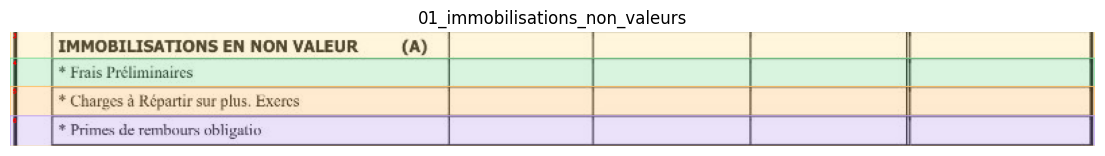

Groupe : 02_immobilisations_incorporelles


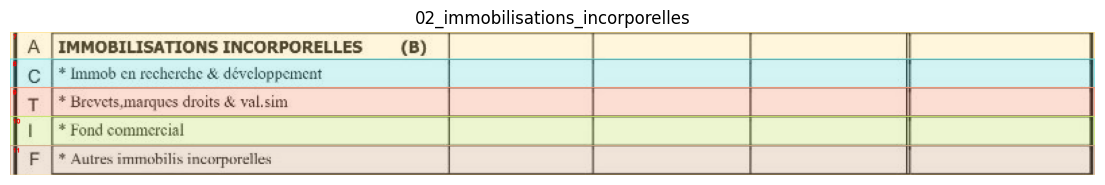

Groupe : 03_immobilisations_corporelles


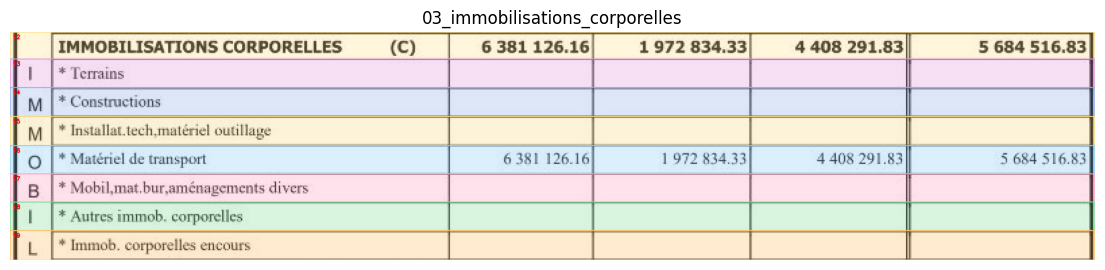

Groupe : 04_immobilisations_financieres


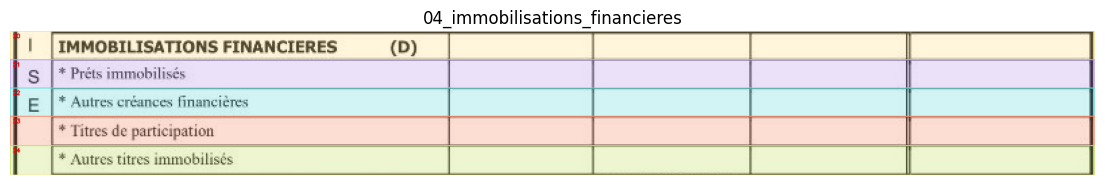

Groupe : 05_ecart_conversion_actif


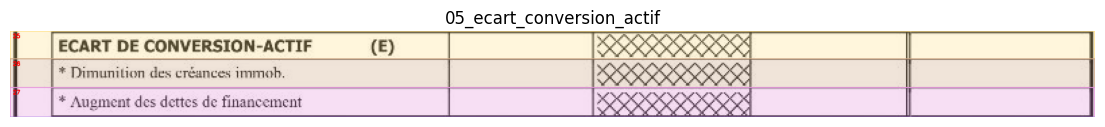

Groupe : 06_total_I


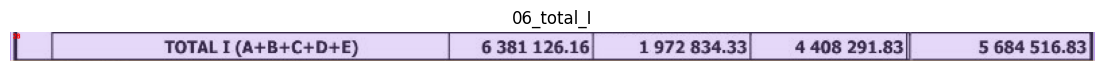

Groupe : 07_stocks


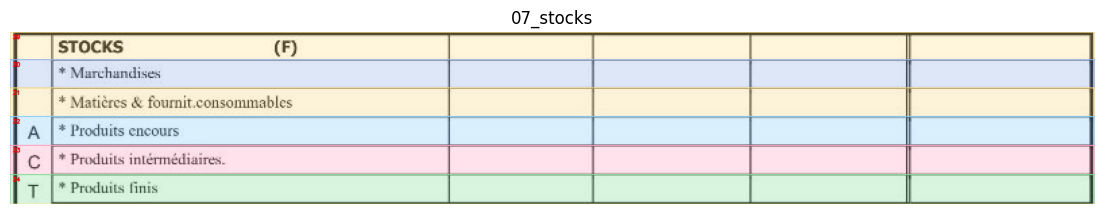

Groupe : 08_creances_actif_circulant


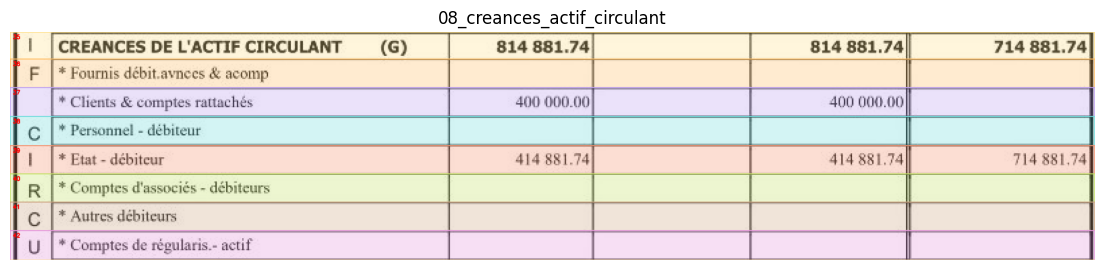

Groupe : 09_titres_valeurs_placement


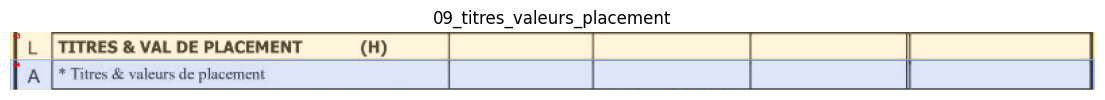

Groupe : 10_ecart_conversion_circulant


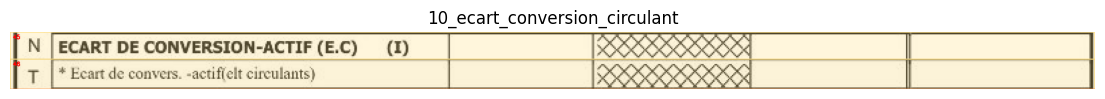

Groupe : 11_total_II


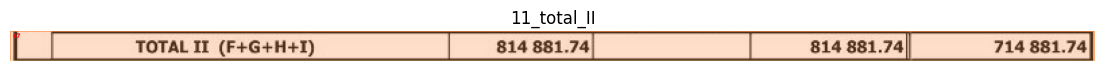

Groupe : 12_tresorerie_actif


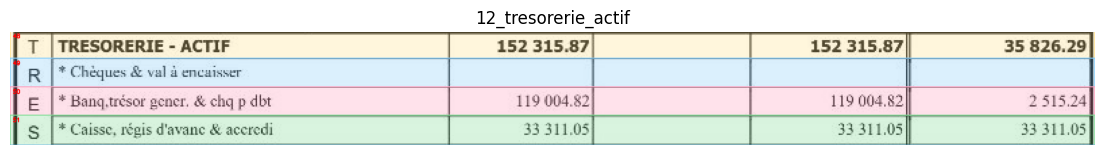

Groupe : 13_total_III


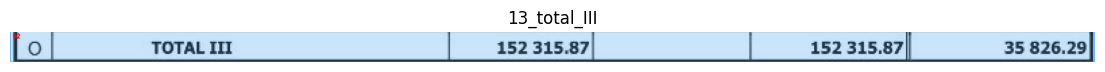

Groupe : 14_total_general


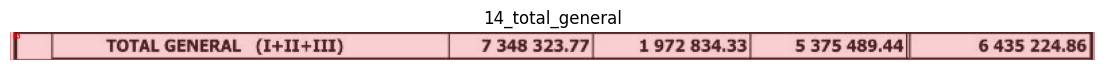

Nombre de groupes : 14


In [9]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

output_dir = Path("/kaggle/working/groupes_colores")
output_dir.mkdir(parents=True, exist_ok=True)

groupes = {
    "01_immobilisations_non_valeurs": (3, 6),
    "02_immobilisations_incorporelles": (7, 11),
    "03_immobilisations_corporelles": (12, 19),
    "04_immobilisations_financieres": (20, 24),
    "05_ecart_conversion_actif": (25, 27),
    "06_total_I": (28, 28),

    "07_stocks": (29, 34),
    "08_creances_actif_circulant": (35, 42),
    "09_titres_valeurs_placement": (43, 44),
    "10_ecart_conversion_circulant": (45, 46),
    "11_total_II": (47, 47),

    "12_tresorerie_actif": (48, 51),
    "13_total_III": (52, 52),
    "14_total_general": (53, 53)
}

row_lookup = {
    row["id_ligne"]: row
    for row in rows_info
}

for nom, (start_id, end_id) in groupes.items():

    selection = [
        row_lookup[i]
        for i in range(start_id, end_id + 1)
    ]

    y1 = min(row["y1"] for row in selection)
    y2 = max(row["y2"] for row in selection)

    group_image = colored[y1:y2, :].copy()

    path = output_dir / f"{nom}.png"
    Image.fromarray(group_image).save(path)

    print("Groupe :", nom)

    plt.figure(figsize=(14, 3))
    plt.imshow(group_image)
    plt.title(nom)
    plt.axis("off")
    plt.show()

print("Nombre de groupes :", len(list(output_dir.glob("*.png"))))

Images préparées : 14


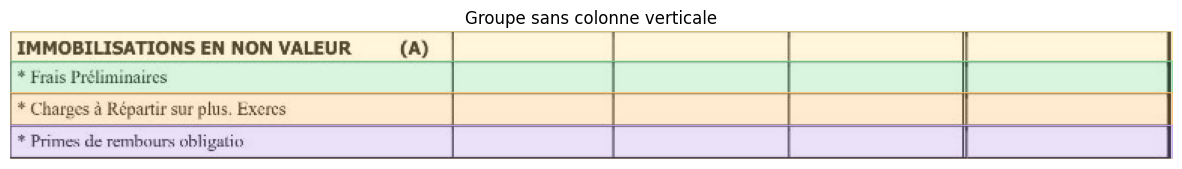

In [10]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

input_dir = Path("/kaggle/working/groupes_colores")
output_dir = Path("/kaggle/working/groupes_vlm")

output_dir.mkdir(parents=True, exist_ok=True)

xs = sorted(column_boundaries)

x_start = xs[1]

for path in sorted(input_dir.glob("*.png")):

    image = Image.open(path).convert("RGB")

    img = image.crop((
        x_start,
        0,
        image.width,
        image.height
    ))

    img.save(output_dir / path.name)

print("Images préparées :", len(list(output_dir.glob("*.png"))))

first_image = sorted(output_dir.glob("*.png"))[0]

plt.figure(figsize=(15, 4))
plt.imshow(Image.open(first_image))
plt.title("Groupe sans colonne verticale")
plt.axis("off")
plt.show()

Images V3 : 14


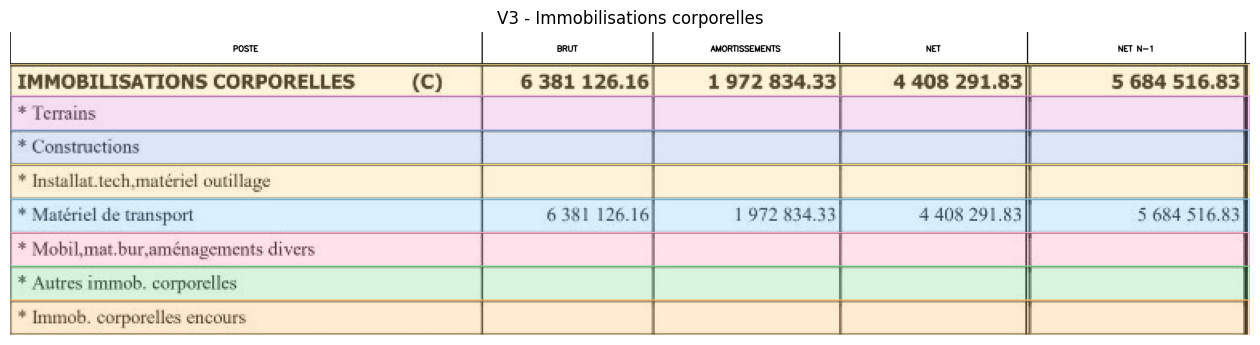

In [11]:
import cv2
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

input_dir = Path("/kaggle/working/groupes_vlm")
output_dir = Path("/kaggle/working/groupes_vlm_v3")

output_dir.mkdir(parents=True, exist_ok=True)

xs = sorted(column_boundaries)

x_start = xs[1]

column_positions = [
    0,
    xs[2] - x_start,
    xs[3] - x_start,
    xs[4] - x_start,
    xs[5] - x_start,
    xs[6] - x_start
]

headers = [
    "POSTE",
    "BRUT",
    "AMORTISSEMENTS",
    "NET",
    "NET N-1"
]

for path in sorted(input_dir.glob("*.png")):

    image = np.array(
        Image.open(path).convert("RGB")
    )

    h, w = image.shape[:2]

    header_h = 80

    assert column_positions[-1] <= w, (
        f"Colonnes hors image : {path.name}"
    )

    header = np.ones(
        (header_h, w, 3),
        dtype=np.uint8
    ) * 255

    for x in column_positions:
        if 0 <= x < w:
            cv2.line(
                header,
                (x, 0),
                (x, header_h - 1),
                (0, 0, 0),
                2
            )

    for i, name in enumerate(headers):

        x1 = column_positions[i]
        x2 = column_positions[i + 1]

        font = cv2.FONT_HERSHEY_SIMPLEX
        scale = 0.65
        thickness = 2

        text_width = cv2.getTextSize(
            name, font, scale, thickness
        )[0][0]

        x_text = (x1 + x2 - text_width) // 2

        cv2.putText(
            header,
            name,
            (x_text, 48),
            font,
            scale,
            (0, 0, 0),
            thickness
        )

    cv2.line(
        header,
        (0, header_h - 1),
        (w - 1, header_h - 1),
        (0, 0, 0),
        2
    )

    final_image = np.vstack([
        header,
        image
    ])

    Image.fromarray(final_image).save(
        output_dir / path.name
    )

image_paths_v3 = sorted(output_dir.glob("*.png"))

print("Images V3 :", len(image_paths_v3))

assert len(image_paths_v3) == 14

# Afficher un groupe contenant plusieurs montants
test_image = output_dir / "03_immobilisations_corporelles.png"

plt.figure(figsize=(16, 5))
plt.imshow(Image.open(test_image))
plt.title("V3 - Immobilisations corporelles")
plt.axis("off")
plt.show()

In [ ]:
# ==========================================
# CONFIGURATION DES 14 GROUPES DU BILAN ACTIF
# ==========================================

GROUPES = {
    "01_immobilisations_non_valeurs":
        ("IMMOBILISATIONS EN NON VALEUR (A)", 4),

    "02_immobilisations_incorporelles":
        ("IMMOBILISATIONS INCORPORELLES (B)", 5),

    "03_immobilisations_corporelles":
        ("IMMOBILISATIONS CORPORELLES (C)", 8),

    "04_immobilisations_financieres":
        ("IMMOBILISATIONS FINANCIERES (D)", 5),

    "05_ecart_conversion_actif":
        ("ECART DE CONVERSION-ACTIF (E)", 3),

    "06_total_I":
        ("TOTAL I (A+B+C+D+E)", 1),

    "07_stocks":
        ("STOCKS (F)", 6),

    "08_creances_actif_circulant":
        ("CREANCES DE L'ACTIF CIRCULANT (G)", 8),

    "09_titres_valeurs_placement":
        ("TITRES & VAL. DE PLACEMENT (H)", 2),

    "10_ecart_conversion_circulant":
        ("ECART DE CONVERSION-ACTIF (E.C) (I)", 2),

    "11_total_II":
        ("TOTAL II (F+G+H+I)", 1),

    "12_tresorerie_actif":
        ("TRESORERIE - ACTIF", 4),

    "13_total_III":
        ("TOTAL III", 1),

    "14_total_general":
        ("TOTAL GENERAL (I+II+III)", 1)
}

print("GROUPES chargés :", len(GROUPES))

# Vérifier que les images V3 sont disponibles
from pathlib import Path

input_dir = Path("/kaggle/working/groupes_vlm_v3")

for groupe_id in GROUPES:
    image_path = input_dir / f"{groupe_id}.png"

    print(
        "✅" if image_path.exists() else "❌",
        image_path.name
    )

print(
    "\nTotal des lignes attendues :",
    sum(nb_lignes for _, nb_lignes in GROUPES.values())
)

In [12]:
%pip install -q -U qwen-vl-utils

Note: you may need to restart the kernel to use updated packages.


In [16]:
def create_prompt_v7(group_name, expected_rows):

    return f"""
Tu es un expert en extraction de tableaux financiers marocains.

DOCUMENT : BILAN ACTIF MAROCAIN.

NOM EXACT DU GROUPE : {group_name}
NOMBRE EXACT DE LIGNES FINANCIÈRES : {expected_rows}

MISSION :
Transformer chaque bande horizontale colorée
en un objet JSON, sans perdre aucune ligne.

==================================================
RÈGLE N°1 — OBLIGATION ABSOLUE
==================================================

LE TITRE DU GROUPE EST UNE LIGNE FINANCIÈRE.

Le groupe contient EXACTEMENT {expected_rows} lignes,
dont UNE ligne principale et {expected_rows - 1}
autres lignes financières.

Le premier objet de "lignes" DOIT être :

id_ligne = 1
poste = "{group_name}"

IMPORTANT :

Le titre "{group_name}" est fourni explicitement
dans ce prompt comme métadonnée du document.

Tu dois UTILISER ce nom pour le champ "poste"
du PREMIER objet JSON.

Il ne suffit PAS de le placer dans le champ "groupe".

Le titre doit apparaître DEUX FOIS :

1. Dans le champ "groupe" du JSON principal.
2. Dans le champ "poste" du PREMIER objet de "lignes".

CES DEUX EMPLACEMENTS SONT OBLIGATOIRES.

Ne commence jamais "lignes" directement par
une sous-ligne financière.

Ne commence jamais directement par :
"Marchandises", "Terrains", "Constructions"
ou une autre sous-ligne si elle appartient au groupe.

==================================================
RÈGLE N°2 — PREMIÈRE BANDE COLORÉE
==================================================

La première bande colorée sous les en-têtes
correspond à la ligne principale du groupe.

Tu dois :

1. Créer obligatoirement l'objet id_ligne = 1.
2. Mettre "poste": "{group_name}".
3. Lire les quatre cellules numériques
   de cette première bande dans l'image.
4. Retourner null pour les cellules vides.

Même si cette première bande ne contient
AUCUN MONTANT, elle doit être conservée.

Ne l'ignore pas parce qu'elle est en gras.
Ne l'ignore pas parce qu'elle est en majuscules.
Ne l'ignore pas parce qu'elle ressemble à un titre.

Un titre financier n'est pas un en-tête artificiel.

==================================================
RÈGLE N°3 — EXTRACTION DES AUTRES LIGNES
==================================================

Après la ligne principale, extrais les
{expected_rows - 1} autres bandes financières.

Lis toutes les bandes colorées de haut en bas.

Chaque bande colorée = UN objet JSON.

Les identifiants doivent suivre l'ordre :

1, 2, 3, ... jusqu'à {expected_rows}.

Ne saute aucune ligne, même si elle ne contient
aucune valeur numérique.

N'invente aucun libellé de sous-ligne.
Si un libellé est illisible, retourne null,
mais conserve l'objet correspondant.

==================================================
RÈGLE N°4 — COLONNES
==================================================

L'image possède cinq colonnes :

POSTE | BRUT | AMORTISSEMENTS | NET | NET N-1

Correspondance JSON :

POSTE = poste
BRUT = brut
AMORTISSEMENTS = amortissements
NET = net
NET N-1 = net_precedent

Les en-têtes artificiels ajoutés en haut
ne doivent PAS être extraits.

Les titres financiers colorés sont des données
et doivent être extraits.

Chaque montant doit rester dans sa colonne.

Ne décale jamais un montant lorsqu'une cellule
intermédiaire est vide.

==================================================
RÈGLE N°5 — GROUPES SANS MONTANTS
==================================================

CERTAINS GROUPES SONT ENTIÈREMENT VIDES
DANS LEURS COLONNES NUMÉRIQUES.

C'EST NORMAL.

UNE LIGNE SANS MONTANT RESTE UNE LIGNE FINANCIÈRE.

Chaque objet JSON doit contenir EXACTEMENT :

"id_ligne"
"poste"
"brut"
"amortissements"
"net"
"net_precedent"

Si une cellule numérique est vide :

Utilise null.

Ne supprime jamais une clé.
Ne remplace jamais null par "".
Ne remplace jamais null par 0.

Même si TOUTES les cellules numériques
du groupe sont vides, retourne obligatoirement
les {expected_rows} lignes financières.

==================================================
RÈGLE N°6 — VALEURS FINANCIÈRES
==================================================

Lis les montants uniquement dans l'image.

Les montants doivent être des chaînes de caractères.

Ne calcule rien.
Ne corrige rien.
N'invente rien.
Ne complète aucune valeur à partir d'autres lignes.

Une cellule hachurée sans chiffre vaut null.

Chaque montant doit être associé à sa bande
et à sa colonne correspondante.

==================================================
RÈGLE N°7 — VÉRIFICATION FINALE
==================================================

AVANT DE GÉNÉRER TA RÉPONSE :

Vérifie obligatoirement :

1. Le champ "groupe" vaut "{group_name}".

2. Le premier objet possède id_ligne = 1.

3. Le premier objet possède
   "poste": "{group_name}".

4. Le premier objet contient aussi les
   quatre champs numériques.

5. La liste contient {expected_rows} objets.

6. Les identifiants vont de 1 à {expected_rows}.

7. Toutes les sous-lignes visibles sont présentes.

8. Aucun champ numérique obligatoire ne manque.

9. Toutes les cellules vides sont null.

10. Tous les montants proviennent de l'image.

Si le PREMIER objet est absent,
la réponse est INCOMPLÈTE.

Si le nombre de lignes est différent de
{expected_rows}, la réponse est INCOMPLÈTE.

==================================================
FORMAT JSON FINAL
==================================================

Retourne un seul objet JSON valide :

{{
    "groupe": "{group_name}",
    "lignes": [
        {{
            "id_ligne": 1,
            "poste": "{group_name}",
            "brut": null,
            "amortissements": null,
            "net": null,
            "net_precedent": null
        }}
    ]
}}

ATTENTION :

Cet exemple représente le début de la structure,
PAS le résultat complet.

Il faut ajouter les autres lignes observées
jusqu'à obtenir {expected_rows} objets.

Les valeurs null de l'exemple doivent être remplacées
par les montants réels lorsqu'ils sont visibles.

PRIORITÉ ABSOLUE :
LE PREMIER OBJET CONTIENT LE TITRE DU GROUPE.
AUCUNE LIGNE FINANCIÈRE NE DOIT ÊTRE OUBLIÉE.

Réponds exclusivement avec le JSON complet.

PAS de Markdown.
PAS d'explication.
PAS de commentaire.
"""

In [18]:
%pip install -q -U "bitsandbytes>=0.46.1" accelerate qwen-vl-utils

Note: you may need to restart the kernel to use updated packages.


In [19]:
import torch
import gc

from transformers import (
    Qwen2_5_VLForConditionalGeneration,
    AutoProcessor,
    BitsAndBytesConfig
)

from qwen_vl_utils import process_vision_info

# ========================================
# CONFIGURATION
# ========================================

model_name = "Qwen/Qwen2.5-VL-7B-Instruct"

assert torch.cuda.is_available(), "Active le GPU Kaggle"

print("GPU :", torch.cuda.get_device_name(0))

compute_dtype = (
    torch.bfloat16
    if torch.cuda.is_bf16_supported()
    else torch.float16
)

# ========================================
# QUANTIFICATION 4 BITS
# ========================================

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=compute_dtype,
    bnb_4bit_use_double_quant=True
)

# ========================================
# CHARGEMENT DU MODÈLE
# ========================================

model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    model_name,
    quantization_config=quantization_config,
    device_map="auto",
    dtype=compute_dtype,
    attn_implementation="sdpa"
)

# ========================================
# PROCESSEUR D'IMAGES
# ========================================

processor = AutoProcessor.from_pretrained(
    model_name,
    min_pixels=256 * 28 * 28,
    max_pixels=1280 * 28 * 28
)

model.eval()

print("\n===== MODÈLE PRÊT =====")
print("Modèle :", model_name)
print("Quantification : NF4 - 4 bits")
print("Précision de calcul :", compute_dtype)
print("Répartition GPU :", model.hf_device_map)

GPU : Tesla T4


config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/57.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

... (4 outputs left out)

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]


===== MODÈLE PRÊT =====
Modèle : Qwen/Qwen2.5-VL-7B-Instruct
Quantification : NF4 - 4 bits
Précision de calcul : torch.bfloat16
Répartition GPU : {'model.visual': 0, 'model.language_model.embed_tokens': 0, 'model.language_model.layers.0': 0, 'model.language_model.layers.1': 0, 'model.language_model.layers.2': 0, 'model.language_model.layers.3': 0, 'model.language_model.layers.4': 0, 'model.language_model.layers.5': 0, 'model.language_model.layers.6': 0, 'model.language_model.layers.7': 0, 'model.language_model.layers.8': 0, 'model.language_model.layers.9': 0, 'model.language_model.layers.10': 0, 'model.language_model.layers.11': 1, 'model.language_model.layers.12': 1, 'model.language_model.layers.13': 1, 'model.language_model.layers.14': 1, 'model.language_model.layers.15': 1, 'model.language_model.layers.16': 1, 'model.language_model.layers.17': 1, 'model.language_model.layers.18': 1, 'model.language_model.layers.19': 1, 'model.language_model.layers.20': 1, 'model.language_model.laye

In [22]:
import torch
import json
import re
import time
import gc
import pandas as pd

from pathlib import Path
from PIL import Image
from qwen_vl_utils import process_vision_info

# =====================================================
# 1. CONFIGURATION
# =====================================================

input_dir = Path(
    "/kaggle/working/groupes_vlm_v3"
)

output_dir = Path(
    "/kaggle/working/resultats_qwen7b_v7_cibles"
)

output_dir.mkdir(parents=True, exist_ok=True)

# Les 5 groupes problématiques identifiés avec Qwen 3B V7
groupes_test = [
    "08_creances_actif_circulant",
    "09_titres_valeurs_placement",
    "10_ecart_conversion_circulant",
    "11_total_II",
    "12_tresorerie_actif"
]

champs_obligatoires = {
    "id_ligne",
    "poste",
    "brut",
    "amortissements",
    "net",
    "net_precedent"
}

champs_numeriques = [
    "brut",
    "amortissements",
    "net",
    "net_precedent"
]

# Vérifier le modèle chargé
nom_modele = str(
    getattr(model.config, "_name_or_path", "")
)

print("Modèle chargé :", nom_modele)

if nom_modele and "7B" not in nom_modele.upper():
    raise ValueError(
        "Le modèle chargé ne semble pas être Qwen 7B."
    )

model.eval()

resultats = []
groupes_extraits = []

# =====================================================
# 2. EXTRACTION DES 5 IMAGES
# =====================================================

for index, groupe_id in enumerate(groupes_test, start=1):

    print("\n" + "=" * 65)
    print(f"QWEN 7B + PROMPT V7 — GROUPE {index}/5")
    print("=" * 65)

    # -----------------------------------------
    # IMAGE ET INFORMATIONS DU GROUPE
    # -----------------------------------------

    image_path = input_dir / f"{groupe_id}.png"

    assert image_path.exists(), (
        f"Image introuvable : {image_path}"
    )

    group_name, expected_rows = GROUPES[groupe_id]

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    # Utiliser le prompt V7 original
    prompt = create_prompt_v7(
        group_name,
        expected_rows
    )

    print("Groupe :", group_name)
    print("Image :", image_path.name)
    print("Dimensions :", image.size)
    print("Lignes attendues :", expected_rows)

    # -----------------------------------------
    # PRÉPARATION DES ENTRÉES QWEN
    # -----------------------------------------

    messages = [{
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": image
            },
            {
                "type": "text",
                "text": prompt
            }
        ]
    }]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(
        messages
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    print(
        "Grille visuelle :",
        inputs.image_grid_thw[0].tolist()
    )

    # =================================================
    # 3. INFÉRENCE QWEN 7B
    # =================================================

    start = time.perf_counter()

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=2048,
            do_sample=False
        )

    elapsed = time.perf_counter() - start

    trimmed_ids = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(
            inputs.input_ids,
            generated_ids
        )
    ]

    response = processor.batch_decode(
        trimmed_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]

    print("\n===== RÉSULTAT BRUT =====")
    print(response)

    print(f"\nTemps d'inférence : {elapsed:.2f} secondes")

    # =================================================
    # 4. SAUVEGARDE DE LA RÉPONSE
    # =================================================

    raw_path = output_dir / f"{groupe_id}.txt"

    raw_path.write_text(
        response,
        encoding="utf-8"
    )

    clean_response = re.sub(
        r"^```(?:json)?\s*|\s*```$",
        "",
        response.strip(),
        flags=re.IGNORECASE
    ).strip()

    json_path = output_dir / f"{groupe_id}.json"

    if json_path.exists():
        json_path.unlink()

    # =================================================
    # 5. VALIDATION AUTOMATIQUE
    # =================================================

    erreurs = []
    nb_lignes = None
    titre_ok = False

    try:

        data = json.loads(clean_response)

        if not isinstance(data, dict):
            raise ValueError("JSON principal incorrect")

        lignes = data.get("lignes")

        if not isinstance(lignes, list):
            raise ValueError("Liste 'lignes' incorrecte")

        nb_lignes = len(lignes)

        # Nombre de lignes
        if nb_lignes != expected_rows:
            erreurs.append(
                f"Nombre de lignes : {nb_lignes}/{expected_rows}"
            )

        # Vérification du titre principal
        if lignes and isinstance(lignes[0], dict):

            titre_ok = (
                lignes[0].get("poste") == group_name
            )

        if not titre_ok:
            erreurs.append("Titre principal incorrect")

        # Vérification de toutes les lignes
        for i, ligne in enumerate(lignes, start=1):

            if not isinstance(ligne, dict):
                erreurs.append(
                    f"Ligne {i} : objet JSON incorrect"
                )
                continue

            manquants = champs_obligatoires - ligne.keys()

            if manquants:
                erreurs.append(
                    f"Ligne {i} : champs manquants {manquants}"
                )

            if ligne.get("id_ligne") != i:
                erreurs.append(
                    f"Ligne {i} : identifiant incorrect"
                )

            for champ in champs_numeriques:

                if champ not in ligne:
                    continue

                valeur = ligne[champ]

                if valeur is not None:

                    if not isinstance(valeur, str):
                        erreurs.append(
                            f"Ligne {i} : {champ} n'est pas une chaîne"
                        )

                    elif not valeur.strip():
                        erreurs.append(
                            f"Ligne {i} : {champ} est vide"
                        )

        # Vérifier les titres répétés
        if len(lignes) >= 2:

            ligne1 = lignes[0]
            ligne2 = lignes[1]

            if isinstance(ligne1, dict) and isinstance(ligne2, dict):

                poste1 = ligne1.get("poste")
                poste2 = ligne2.get("poste")

                if (
                    isinstance(poste1, str)
                    and isinstance(poste2, str)
                    and poste1.strip().casefold()
                    == poste2.strip().casefold()
                ):
                    erreurs.append(
                        "Titre principal répété en ligne 2"
                    )

        # Sauvegarder le JSON sans corriger les valeurs
        with open(json_path, "w", encoding="utf-8") as f:
            json.dump(
                data,
                f,
                ensure_ascii=False,
                indent=2
            )

        groupes_extraits.append(data)

        statut = (
            "STRUCTURE CONFORME"
            if not erreurs
            else "À VÉRIFIER"
        )

    except (json.JSONDecodeError, ValueError) as e:

        erreurs.append(str(e))
        statut = "JSON INVALIDE"

    # =================================================
    # 6. DIAGNOSTIC
    # =================================================

    print("\n===== DIAGNOSTIC QWEN 7B =====")

    print("Lignes attendues :", expected_rows)
    print("Lignes extraites :", nb_lignes)
    print("Titre principal correct :", titre_ok)
    print("Statut :", statut)

    if erreurs:
        for erreur in erreurs:
            print("❌", erreur)
    else:
        print("✅ Aucun problème structurel détecté")

    resultats.append({
        "groupe": group_name,
        "lignes_attendues": expected_rows,
        "lignes_extraites": nb_lignes,
        "titre_correct": titre_ok,
        "statut": statut,
        "nb_erreurs": len(erreurs),
        "details_erreurs": " | ".join(erreurs),
        "temps_secondes": round(elapsed, 2)
    })

    # =================================================
    # 7. LIBÉRER LA MÉMOIRE TEMPORAIRE
    # =================================================

    del inputs, generated_ids, trimmed_ids
    del image_inputs, video_inputs

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# =====================================================
# 8. TABLEAU RÉCAPITULATIF
# =====================================================

df_7b = pd.DataFrame(resultats)

print("\n" + "=" * 65)
print("RÉSUMÉ — QWEN 7B / PROMPT V7")
print("=" * 65)

display(df_7b)

print("\nGroupes testés :", len(resultats))

print(
    "Structures conformes :",
    (df_7b["statut"] == "STRUCTURE CONFORME").sum()
)

print(
    "Lignes attendues :",
    df_7b["lignes_attendues"].sum()
)

print(
    "Lignes extraites :",
    df_7b["lignes_extraites"].sum()
)

print(
    "Temps total :",
    round(df_7b["temps_secondes"].sum(), 2),
    "secondes"
)

df_7b.to_csv(
    output_dir / "statistiques_qwen7b_v7.csv",
    index=False
)

# =====================================================
# 9. FUSION DES JSON
# =====================================================

final_data = {
    "document": "Bilan Actif",
    "modele": "Qwen2.5-VL-7B-Instruct",
    "prompt": "V7",
    "groupes_testes": groupes_test,
    "groupes": groupes_extraits
}

final_path = output_dir / "bilan_actif_7b_v7_cibles.json"

with open(final_path, "w", encoding="utf-8") as f:
    json.dump(
        final_data,
        f,
        ensure_ascii=False,
        indent=2
    )

print("\n===== EXTRACTION TERMINÉE =====")
print("JSON final :", final_path)
print("Statistiques :", output_dir / "statistiques_qwen7b_v7.csv")
print("Groupes sauvegardés :", len(groupes_extraits))

Modèle chargé : Qwen/Qwen2.5-VL-7B-Instruct

QWEN 7B + PROMPT V7 — GROUPE 1/5
Groupe : CREANCES DE L'ACTIF CIRCULANT (G)
Image : 08_creances_actif_circulant.png
Dimensions : (3108, 759)
Lignes attendues : 8


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


Grille visuelle : [1, 34, 144]

===== RÉSULTAT BRUT =====
```json
{
    "groupe": "CREANCES DE L'ACTIF CIRCULANT (G)",
    "lignes": [
        {
            "id_ligne": 1,
            "poste": "CREANCES DE L'ACTIF CIRCULANT (G)",
            "brut": "814 881.74",
            "amortissements": null,
            "net": "814 881.74",
            "net_precedent": "714 881.74"
        },
        {
            "id_ligne": 2,
            "poste": "Fournis débit.avnces & accomp",
            "brut": null,
            "amortissements": null,
            "net": null,
            "net_precedent": null
        },
        {
            "id_ligne": 3,
            "poste": "Clients & comptes rattachés",
            "brut": "400 000.00",
            "amortissements": null,
            "net": "400 000.00",
            "net_precedent": null
        },
        {
            "id_ligne": 4,
            "poste": "Personnel - débiteur",
            "brut": null,
            "amortissements": null,
          

,groupe,lignes_attendues,lignes_extraites,titre_correct,statut,nb_erreurs,details_erreurs,temps_secondes
0,CREANCES DE L'ACTIF CIRCULANT (G),8,8,True,STRUCTURE CONFORME,0,,93.04
1,TITRES & VAL. DE PLACEMENT (H),2,2,True,STRUCTURE CONFORME,0,,36.52
2,ECART DE CONVERSION-ACTIF (E.C) (I),2,2,True,STRUCTURE CONFORME,0,,39.23
3,TOTAL II (F+G+H+I),1,1,True,STRUCTURE CONFORME,0,,29.68
4,TRESORERIE - ACTIF,4,4,True,STRUCTURE CONFORME,0,,65.26



Groupes testés : 5
Structures conformes : 5
Lignes attendues : 17
Lignes extraites : 17
Temps total : 263.73 secondes

===== EXTRACTION TERMINÉE =====
JSON final : /kaggle/working/resultats_qwen7b_v7_cibles/bilan_actif_7b_v7_cibles.json
Statistiques : /kaggle/working/resultats_qwen7b_v7_cibles/statistiques_qwen7b_v7.csv
Groupes sauvegardés : 5


In [23]:
import torch
import json
import re
import time
import gc
import pandas as pd

from pathlib import Path
from PIL import Image
from qwen_vl_utils import process_vision_info

# =====================================================
# 1. CONFIGURATION
# =====================================================

input_dir = Path(
    "/kaggle/working/groupes_vlm_v3"
)

output_dir = Path(
    "/kaggle/working/resultats_qwen7b_v7_restants"
)

output_dir.mkdir(parents=True, exist_ok=True)

# Les 9 groupes qui restent à tester
groupes_test = [
    "01_immobilisations_non_valeurs",
    "02_immobilisations_incorporelles",
    "03_immobilisations_corporelles",
    "04_immobilisations_financieres",
    "05_ecart_conversion_actif",
    "06_total_I",
    "07_stocks",
    "13_total_III",
    "14_total_general"
]

assert len(groupes_test) == 9

# Vérifier les éléments nécessaires
assert "model" in globals(), "Modèle non chargé"
assert "processor" in globals(), "Processor non chargé"
assert "GROUPES" in globals(), "GROUPES non défini"
assert "create_prompt_v7" in globals(), "Prompt V7 non défini"

model_name = str(
    getattr(model.config, "_name_or_path", "")
)

print("Modèle chargé :", model_name)

assert "7b" in model_name.lower(), (
    "Le modèle chargé doit être Qwen 7B"
)

champs_numeriques = [
    "brut",
    "amortissements",
    "net",
    "net_precedent"
]

champs_obligatoires = {
    "id_ligne",
    "poste",
    "brut",
    "amortissements",
    "net",
    "net_precedent"
}

resultats = []
groupes_extraits = []

model.eval()

# =====================================================
# 2. INFÉRENCE SUR LES 9 GROUPES
# =====================================================

for index, groupe_id in enumerate(groupes_test, start=1):

    print("\n" + "=" * 65)
    print(f"QWEN 7B + V7 — GROUPE {index}/9")
    print("=" * 65)

    group_name, expected_rows = GROUPES[groupe_id]

    image_path = input_dir / f"{groupe_id}.png"

    assert image_path.exists(), (
        f"Image introuvable : {image_path}"
    )

    # ==========================================
    # IMAGE ET PROMPT
    # ==========================================

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    prompt = create_prompt_v7(
        group_name,
        expected_rows
    )

    print("Image :", image_path.name)
    print("Groupe :", group_name)
    print("Dimensions :", image.size)
    print("Lignes attendues :", expected_rows)

    # ==========================================
    # PRÉPARATION QWEN
    # ==========================================

    messages = [{
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": image
            },
            {
                "type": "text",
                "text": prompt
            }
        ]
    }]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(
        messages
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    print(
        "Grille visuelle :",
        inputs.image_grid_thw[0].tolist()
    )

    # ==========================================
    # INFÉRENCE QWEN 7B
    # ==========================================

    start = time.perf_counter()

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=2048,
            do_sample=False
        )

    elapsed = time.perf_counter() - start

    trimmed_ids = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(
            inputs.input_ids,
            generated_ids
        )
    ]

    response = processor.batch_decode(
        trimmed_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]

    print("\n===== RÉSULTAT BRUT =====")
    print(response)

    print(f"\nTemps : {elapsed:.2f} secondes")

    # ==========================================
    # SAUVEGARDE RÉPONSE BRUTE
    # ==========================================

    raw_path = output_dir / f"{groupe_id}.txt"

    raw_path.write_text(
        response,
        encoding="utf-8"
    )

    clean_response = re.sub(
        r"^```(?:json)?\s*|\s*```$",
        "",
        response.strip(),
        flags=re.IGNORECASE
    ).strip()

    json_path = output_dir / f"{groupe_id}.json"

    if json_path.exists():
        json_path.unlink()

    # ==========================================
    # VALIDATION SANS CORRECTION
    # ==========================================

    erreurs = []
    nb_lignes = None
    titre_ok = False

    try:

        data = json.loads(clean_response)

        if not isinstance(data, dict):
            raise ValueError("Objet JSON principal invalide")

        lignes = data.get("lignes")

        if not isinstance(lignes, list):
            raise ValueError("Liste 'lignes' invalide")

        nb_lignes = len(lignes)

        if data.get("groupe") != group_name:
            erreurs.append("Nom du groupe incorrect")

        if nb_lignes != expected_rows:
            erreurs.append(
                f"Nombre de lignes : {nb_lignes}/{expected_rows}"
            )

        # Vérifier le titre principal
        if lignes and isinstance(lignes[0], dict):

            titre_ok = (
                lignes[0].get("poste") == group_name
            )

        if not titre_ok:
            erreurs.append("Titre principal incorrect")

        # Vérifier toutes les lignes
        for i, ligne in enumerate(lignes, start=1):

            if not isinstance(ligne, dict):
                erreurs.append(
                    f"Ligne {i} : objet incorrect"
                )
                continue

            manquants = champs_obligatoires - ligne.keys()

            if manquants:
                erreurs.append(
                    f"Ligne {i} : champs manquants {manquants}"
                )

            if ligne.get("id_ligne") != i:
                erreurs.append(
                    f"Ligne {i} : ID incorrect"
                )

            for champ in champs_numeriques:

                if champ not in ligne:
                    continue

                valeur = ligne[champ]

                if valeur is not None:

                    if not isinstance(valeur, str):
                        erreurs.append(
                            f"Ligne {i} : {champ} "
                            "n'est pas une chaîne"
                        )

                    elif not valeur.strip():
                        erreurs.append(
                            f"Ligne {i} : {champ} "
                            "est une chaîne vide"
                        )

        # Détecter un titre répété
        if len(lignes) >= 2:

            ligne1 = lignes[0]
            ligne2 = lignes[1]

            if (
                isinstance(ligne1, dict)
                and isinstance(ligne2, dict)
                and isinstance(ligne1.get("poste"), str)
                and isinstance(ligne2.get("poste"), str)
                and ligne1["poste"].strip().casefold()
                == ligne2["poste"].strip().casefold()
            ):
                erreurs.append(
                    "Titre principal répété à la ligne 2"
                )

        # Sauvegarde sans correction manuelle
        with open(json_path, "w", encoding="utf-8") as f:

            json.dump(
                data,
                f,
                ensure_ascii=False,
                indent=2
            )

        groupes_extraits.append(data)

        statut = (
            "STRUCTURE CONFORME"
            if not erreurs
            else "À VÉRIFIER"
        )

    except (json.JSONDecodeError, ValueError) as e:

        erreurs.append(str(e))
        statut = "JSON INVALIDE"

    # ==========================================
    # DIAGNOSTIC
    # ==========================================

    print("\n===== DIAGNOSTIC =====")

    print("Groupe :", group_name)
    print("Lignes attendues :", expected_rows)
    print("Lignes extraites :", nb_lignes)
    print("Titre correct :", titre_ok)
    print("Statut :", statut)

    if erreurs:
        for erreur in erreurs:
            print("❌", erreur)
    else:
        print("✅ Aucun problème structurel détecté")

    resultats.append({
        "groupe": group_name,
        "lignes_attendues": expected_rows,
        "lignes_extraites": nb_lignes,
        "titre_correct": titre_ok,
        "statut": statut,
        "nb_erreurs": len(erreurs),
        "details_erreurs": " | ".join(erreurs),
        "temps_secondes": round(elapsed, 2)
    })

    # ==========================================
    # LIBÉRATION MÉMOIRE
    # ==========================================

    del inputs, generated_ids, trimmed_ids
    del image_inputs, video_inputs

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# =====================================================
# 3. TABLEAU DES RÉSULTATS
# =====================================================

df_restants = pd.DataFrame(resultats)

print("\n" + "=" * 65)
print("RÉSUMÉ — QWEN 7B V7 / 9 GROUPES")
print("=" * 65)

display(df_restants)

print("\nGroupes testés :", len(resultats))

print(
    "Structures conformes :",
    (df_restants["statut"] == "STRUCTURE CONFORME").sum()
)

print(
    "Lignes attendues :",
    df_restants["lignes_attendues"].sum()
)

print(
    "Lignes extraites :",
    df_restants["lignes_extraites"].sum()
)

print(
    "Temps total :",
    round(df_restants["temps_secondes"].sum(), 2),
    "secondes"
)

# Sauvegarde statistiques
df_restants.to_csv(
    output_dir / "statistiques_qwen7b_v7_restants.csv",
    index=False
)

# =====================================================
# 4. JSON DES 9 GROUPES
# =====================================================

final_data = {
    "document": "Bilan Actif",
    "modele": "Qwen2.5-VL-7B-Instruct",
    "prompt": "V7",
    "groupes": groupes_extraits
}

final_path = output_dir / "bilan_actif_7b_v7_restants.json"

with open(final_path, "w", encoding="utf-8") as f:

    json.dump(
        final_data,
        f,
        ensure_ascii=False,
        indent=2
    )

print("\n===== EXTRACTION DES 9 GROUPES TERMINÉE =====")

print("JSON :", final_path)
print(
    "Statistiques :",
    output_dir / "statistiques_qwen7b_v7_restants.csv"
)

Modèle chargé : Qwen/Qwen2.5-VL-7B-Instruct

QWEN 7B + V7 — GROUPE 1/9
Image : 01_immobilisations_non_valeurs.png
Groupe : IMMOBILISATIONS EN NON VALEUR (A)
Dimensions : (3108, 421)
Lignes attendues : 4
Grille visuelle : [1, 26, 194]


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(



===== RÉSULTAT BRUT =====
```json
{
    "groupe": "IMMOBILISATIONS EN NON VALEUR (A)",
    "lignes": [
        {
            "id_ligne": 1,
            "poste": "IMMOBILISATIONS EN NON VALEUR (A)",
            "brut": null,
            "amortissements": null,
            "net": null,
            "net_precedent": null
        },
        {
            "id_ligne": 2,
            "poste": "Frais Préliminaires",
            "brut": null,
            "amortissements": null,
            "net": null,
            "net_precedent": null
        },
        {
            "id_ligne": 3,
            "poste": "Charges à Répartir sur plus. Exercs",
            "brut": null,
            "amortissements": null,
            "net": null,
            "net_precedent": null
        },
        {
            "id_ligne": 4,
            "poste": "Primes de rembours obligatio",
            "brut": null,
            "amortissements": null,
            "net": null,
            "net_precedent": null
        }
    ]


,groupe,lignes_attendues,lignes_extraites,titre_correct,statut,nb_erreurs,details_erreurs,temps_secondes
0,IMMOBILISATIONS EN NON VALEUR (A),4,4,True,STRUCTURE CONFORME,0,,55.26
1,IMMOBILISATIONS INCORPORELLES (B),5,5,True,STRUCTURE CONFORME,0,,61.68
2,IMMOBILISATIONS CORPORELLES (C),8,8,True,STRUCTURE CONFORME,0,,94.31
3,IMMOBILISATIONS FINANCIERES (D),5,5,True,STRUCTURE CONFORME,0,,60.84
4,ECART DE CONVERSION-ACTIF (E),3,3,True,STRUCTURE CONFORME,0,,45.67
5,TOTAL I (A+B+C+D+E),1,1,True,STRUCTURE CONFORME,0,,31.72
6,STOCKS (F),6,6,True,STRUCTURE CONFORME,0,,64.51
7,TOTAL III,1,1,True,STRUCTURE CONFORME,0,,27.04
8,TOTAL GENERAL (I+II+III),1,1,True,STRUCTURE CONFORME,0,,31.60



Groupes testés : 9
Structures conformes : 9
Lignes attendues : 34
Lignes extraites : 34
Temps total : 472.63 secondes

===== EXTRACTION DES 9 GROUPES TERMINÉE =====
JSON : /kaggle/working/resultats_qwen7b_v7_restants/bilan_actif_7b_v7_restants.json
Statistiques : /kaggle/working/resultats_qwen7b_v7_restants/statistiques_qwen7b_v7_restants.csv


In [24]:
import json
from pathlib import Path

dossier_5 = Path(
    "/kaggle/working/resultats_qwen7b_v7_cibles"
)

dossier_9 = Path(
    "/kaggle/working/resultats_qwen7b_v7_restants"
)

dossier_final = Path(
    "/kaggle/working/resultats_qwen7b_v7_complet"
)

dossier_final.mkdir(parents=True, exist_ok=True)

# Les groupes déjà testés
ids_5 = {
    "08_creances_actif_circulant",
    "09_titres_valeurs_placement",
    "10_ecart_conversion_circulant",
    "11_total_II",
    "12_tresorerie_actif"
}

bilan_complet = {
    "document": "Bilan Actif",
    "modele": "Qwen2.5-VL-7B-Instruct",
    "prompt": "V7",
    "groupes": []
}

for groupe_id in GROUPES:

    if groupe_id in ids_5:
        dossier = dossier_5
    else:
        dossier = dossier_9

    fichier = dossier / f"{groupe_id}.json"

    assert fichier.exists(), (
        f"JSON manquant : {fichier}"
    )

    with open(fichier, "r", encoding="utf-8") as f:
        data = json.load(f)

    bilan_complet["groupes"].append(data)

fichier_final = (
    dossier_final / "bilan_actif_7b_v7.json"
)

with open(fichier_final, "w", encoding="utf-8") as f:
    json.dump(
        bilan_complet,
        f,
        ensure_ascii=False,
        indent=2
    )

print("===== BILAN ACTIF COMPLET =====")
print("Groupes fusionnés :", len(bilan_complet["groupes"]))

total_lignes = sum(
    len(g["lignes"])
    for g in bilan_complet["groupes"]
)

print("Lignes extraites :", total_lignes)
print("Lignes attendues : 51")
print("JSON final :", fichier_final)

===== BILAN ACTIF COMPLET =====
Groupes fusionnés : 14
Lignes extraites : 51
Lignes attendues : 51
JSON final : /kaggle/working/resultats_qwen7b_v7_complet/bilan_actif_7b_v7.json


In [25]:
print("hello")

hello


# passif  

Page : 2
Dimensions : (5250, 3717, 3)
Séparateurs horizontaux : 54
Frontières verticales : [204, 332, 2426, 2971, 3464]

Lignes financières : 44
01_capitaux_propres — 10 lignes
02_total_capitaux_propres — 1 lignes
03_capitaux_propres_assimiles — 3 lignes
04_dettes_financement — 3 lignes
05_provisions_durables — 3 lignes
06_ecarts_conversion_passif — 3 lignes
07_total_I — 1 lignes
08_dettes_passif_circulant — 9 lignes
09_autres_provisions — 2 lignes
10_ecart_conversion_circulant — 2 lignes
11_total_II — 1 lignes
12_tresorerie_passif — 4 lignes
13_total_III — 1 lignes
14_total_general — 1 lignes

===== SEGMENTATION TERMINÉE =====
Images créées : 14
Dossier : /kaggle/working/groupes_passif_v3


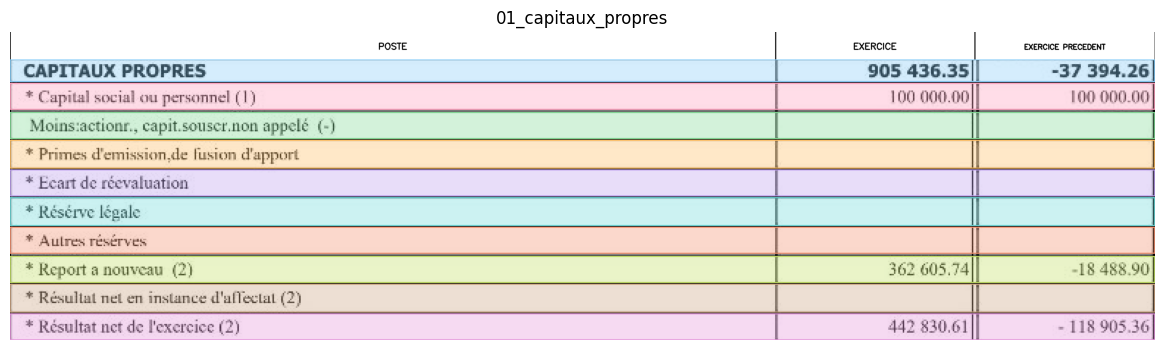

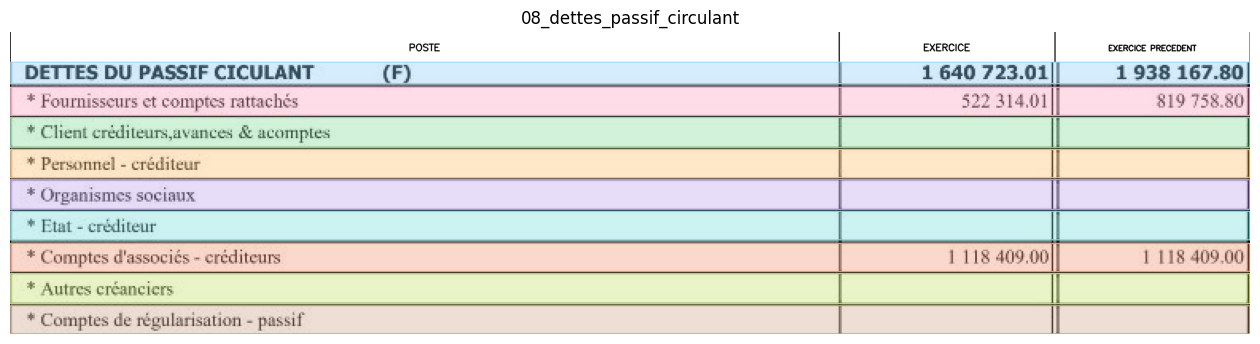

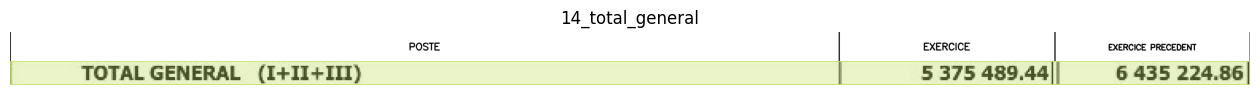

In [26]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pdf2image import convert_from_path
from pathlib import Path
from PIL import Image

# =====================================================
# 1. CHARGER LA PAGE PASSIF
# =====================================================

pdf_files = list(
    Path("/kaggle/input").rglob("bilan_group_2.pdf")
)

assert pdf_files, "PDF introuvable dans Kaggle Input"

pdf_path = str(pdf_files[0])

pages_passif = convert_from_path(
    pdf_path,
    dpi=300,
    first_page=2,
    last_page=2
)

image = np.array(pages_passif[0].convert("RGB"))

H, W = image.shape[:2]

print("Page :", 2)
print("Dimensions :", image.shape)

# =====================================================
# 2. DÉTECTION DES LIGNES DU TABLEAU
# =====================================================

gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

_, binary = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

def regroupement_positions(indices):
    if len(indices) == 0:
        return []

    blocs = np.split(
        indices,
        np.where(np.diff(indices) > 1)[0] + 1
    )

    return [
        (int(b[0]), int(b[-1]))
        for b in blocs
        if len(b) > 0
    ]

# Détecter les lignes horizontales longues
kernel_h = cv2.getStructuringElement(
    cv2.MORPH_RECT,
    (int(W * 0.32), 1)
)

horizontal = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel_h
)

projection_h = (horizontal > 0).sum(axis=1)

positions_h = np.where(
    projection_h > int(W * 0.40)
)[0]

limites_h = regroupement_positions(positions_h)

print("Séparateurs horizontaux :", len(limites_h))

# =====================================================
# 3. DÉTECTION DES COLONNES
# =====================================================

kernel_v = cv2.getStructuringElement(
    cv2.MORPH_RECT, (1, 80)
)

vertical = cv2.morphologyEx(
    binary,
    cv2.MORPH_OPEN,
    kernel_v
)

haut_tableau = limites_h[0][0]
bas_tableau = limites_h[-1][1]

projection_v = (
    vertical[haut_tableau:bas_tableau] > 0
).sum(axis=0)

positions_v = np.where(
    projection_v > int(
        0.52 * (bas_tableau - haut_tableau)
    )
)[0]

colonnes_detectees = regroupement_positions(positions_v)

centres = [
    int(round((a + b) / 2))
    for a, b in colonnes_detectees
]

# Fusionner les doubles bordures proches
xs = []

for x in centres:
    if xs and x - xs[-1] < 25:
        xs[-1] = int(round((xs[-1] + x) / 2))
    else:
        xs.append(x)

print("Frontières verticales :", xs)

assert len(xs) == 5, (
    f"Vérifier les frontières détectées : {xs}"
)

# Première colonne étroite supprimée
_, x_poste, x_exercice, x_precedent, x_fin = xs

# =====================================================
# 4. CONSTRUIRE LES LIGNES FINANCIÈRES
# =====================================================

rows_info_passif = []

# i=0 correspond aux en-têtes d'origine
for i in range(1, len(limites_h) - 1):

    y1 = limites_h[i][1] + 1
    y2 = limites_h[i + 1][0]

    if y2 <= y1 + 12:
        continue

    # Déterminer si la bande contient un poste
    zone_poste = binary[
        y1 + 8:y2 - 8,
        x_poste + 20:x_exercice - 20
    ]

    nb_pixels = np.count_nonzero(zone_poste)

    # Exclure les séparations réellement vides
    if nb_pixels <= 500:
        continue

    rows_info_passif.append({
        "id_ligne": len(rows_info_passif) + 1,
        "y1": y1,
        "y2": y2
    })

print("\nLignes financières :", len(rows_info_passif))

assert len(rows_info_passif) == 44, (
    "Le découpage ne correspond pas aux 44 lignes "
    "vérifiées sur ce document."
)

# =====================================================
# 5. DÉFINITION DES GROUPES PASSIF
# =====================================================

# Structure : nom du groupe, première ligne, dernière ligne
REGIONS_PASSIF = {
    "01_capitaux_propres":
        ("CAPITAUX PROPRES", 1, 10),

    "02_total_capitaux_propres":
        ("TOTAL DES CAPITAUX PROPRES (A)", 11, 11),

    "03_capitaux_propres_assimiles":
        ("CAPITAUX PROPRES ASSIMILES (B)", 12, 14),

    "04_dettes_financement":
        ("DETTES DE FINANCEMENT (C)", 15, 17),

    "05_provisions_durables":
        ("PROVIS. DURABL. PR RISQUES & CHARGES (D)", 18, 20),

    "06_ecarts_conversion_passif":
        ("ECARTS DE CONVERSION - PASSIF (E)", 21, 23),

    "07_total_I":
        ("TOTAL I (A+B+C+D+E)", 24, 24),

    "08_dettes_passif_circulant":
        ("DETTES DU PASSIF CIRCULANT (F)", 25, 33),

    "09_autres_provisions":
        ("AUTRES PROVIS POUR RISQUES & CHARGES (G)", 34, 35),

    "10_ecart_conversion_circulant":
        ("ECART DE CONVERSION - PASSIF (E.CIR (H)", 36, 37),

    "11_total_II":
        ("TOTAL II (F+G+H)", 38, 38),

    "12_tresorerie_passif":
        ("TRESORERIE - PASSIF", 39, 42),

    "13_total_III":
        ("TOTAL III", 43, 43),

    "14_total_general":
        ("TOTAL GENERAL (I+II+III)", 44, 44)
}

GROUPES_PASSIF = {
    cle: (nom, derniere - premiere + 1)
    for cle, (nom, premiere, derniere)
    in REGIONS_PASSIF.items()
}

# =====================================================
# 6. COLORATION ET EN-TÊTES
# =====================================================

PALETTE = [
    (135, 206, 250),
    (255, 160, 190),
    (130, 220, 150),
    (255, 190, 100),
    (190, 160, 240),
    (110, 220, 220),
    (245, 145, 110),
    (195, 225, 100),
    (205, 165, 130),
    (230, 150, 220),
    (145, 175, 230),
    (245, 215, 125)
]

output_dir = Path(
    "/kaggle/working/groupes_passif_v3"
)

output_dir.mkdir(parents=True, exist_ok=True)

headers = [
    "POSTE",
    "EXERCICE",
    "EXERCICE PRECEDENT"
]

for groupe_id, (nom, debut, fin) in REGIONS_PASSIF.items():

    selection = rows_info_passif[debut - 1:fin]

    y_start = selection[0]["y1"]
    y_end = selection[-1]["y2"]

    # Retirer la première colonne étroite
    group_image = image[
        y_start:y_end,
        x_poste:x_fin
    ].copy()

    # Colorer chaque ligne indépendamment
    for j, ligne in enumerate(selection):

        ya = ligne["y1"] - y_start
        yb = ligne["y2"] - y_start

        color = np.array(
            PALETTE[(debut + j - 1) % len(PALETTE)],
            dtype=np.float32
        )

        region = group_image[ya:yb].astype(np.float32)

        group_image[ya:yb] = (
            0.65 * region + 0.35 * color
        ).astype(np.uint8)

        cv2.rectangle(
            group_image,
            (0, ya),
            (group_image.shape[1] - 1, yb - 1),
            tuple(map(int, color)),
            2
        )

    # Créer un en-tête artificiel
    width = group_image.shape[1]
    header_h = 75

    header = np.full(
        (header_h, width, 3),
        255,
        dtype=np.uint8
    )

    positions = [
        0,
        x_exercice - x_poste,
        x_precedent - x_poste,
        x_fin - x_poste
    ]

    for x in positions:
        cv2.line(
            header,
            (x, 0),
            (x, header_h - 1),
            (0, 0, 0),
            2
        )

    for j, titre in enumerate(headers):

        scale = 0.8 if j < 2 else 0.65

        text_width = cv2.getTextSize(
            titre,
            cv2.FONT_HERSHEY_SIMPLEX,
            scale,
            2
        )[0][0]

        x_text = (
            positions[j] +
            positions[j + 1] -
            text_width
        ) // 2

        cv2.putText(
            header,
            titre,
            (x_text, 47),
            cv2.FONT_HERSHEY_SIMPLEX,
            scale,
            (0, 0, 0),
            2
        )

    final_image = np.vstack([
        header,
        group_image
    ])

    path = output_dir / f"{groupe_id}.png"

    Image.fromarray(final_image).save(path)

    print(
        groupe_id,
        "—",
        len(selection),
        "lignes"
    )

print("\n===== SEGMENTATION TERMINÉE =====")
print("Images créées :", len(list(output_dir.glob("*.png"))))
print("Dossier :", output_dir)

# =====================================================
# 7. VISUALISATION
# =====================================================

for groupe_id in [
    "01_capitaux_propres",
    "08_dettes_passif_circulant",
    "14_total_general"
]:
    img = Image.open(output_dir / f"{groupe_id}.png")

    plt.figure(figsize=(16, 4))
    plt.imshow(img)
    plt.title(groupe_id)
    plt.axis("off")
    plt.show()

Images trouvées : 14

PRÉTRAITEMENT PASSIF V5 — 1/14
Image : 01_capitaux_propres.png
Dimensions V3 : (3132, 843)
Séparateur 1 : (2093, 2095)
Séparateur 2 : (2638, 2640)
Dimensions V5 : (3382, 843)
Image sauvegardée : 01_capitaux_propres.png

PRÉTRAITEMENT PASSIF V5 — 2/14
Image : 02_total_capitaux_propres.png
Dimensions V3 : (3132, 143)
Séparateur 1 : (2093, 2095)
Séparateur 2 : (2638, 2640)
Dimensions V5 : (3382, 143)
Image sauvegardée : 02_total_capitaux_propres.png

PRÉTRAITEMENT PASSIF V5 — 3/14
Image : 03_capitaux_propres_assimiles.png
Dimensions V3 : (3132, 296)
Séparateur 1 : (2093, 2095)
Séparateur 2 : (2638, 2640)
Dimensions V5 : (3382, 296)
Image sauvegardée : 03_capitaux_propres_assimiles.png

PRÉTRAITEMENT PASSIF V5 — 4/14
Image : 04_dettes_financement.png
Dimensions V3 : (3132, 300)
Séparateur 1 : (2093, 2095)
Séparateur 2 : (2638, 2640)
Dimensions V5 : (3382, 300)
Image sauvegardée : 04_dettes_financement.png

PRÉTRAITEMENT PASSIF V5 — 5/14
Image : 05_provisions_durables.

,image,largeur_v3,hauteur_v3,largeur_v5,hauteur_v5,separateur_1,separateur_2,statut
0,01_capitaux_propres,3132,843,3382,843,2093,2638,TRAITÉE
1,02_total_capitaux_propres,3132,143,3382,143,2093,2638,TRAITÉE
2,03_capitaux_propres_assimiles,3132,296,3382,296,2093,2638,TRAITÉE
3,04_dettes_financement,3132,300,3382,300,2093,2638,TRAITÉE
4,05_provisions_durables,3132,296,3382,296,2093,2638,TRAITÉE
5,06_ecarts_conversion_passif,3132,296,3382,296,2093,2638,TRAITÉE
6,07_total_I,3132,152,3382,152,2093,2638,TRAITÉE
7,08_dettes_passif_circulant,3132,762,3382,762,2093,2638,TRAITÉE
8,09_autres_provisions,3132,216,3382,216,2093,2638,TRAITÉE
9,10_ecart_conversion_circulant,3132,219,3382,219,2093,2638,TRAITÉE


Images V3 : 14
Images V5 : 14

✅ LES 14 IMAGES PASSIF V5 SONT CRÉÉES
Dossier : /kaggle/working/groupes_passif_v5


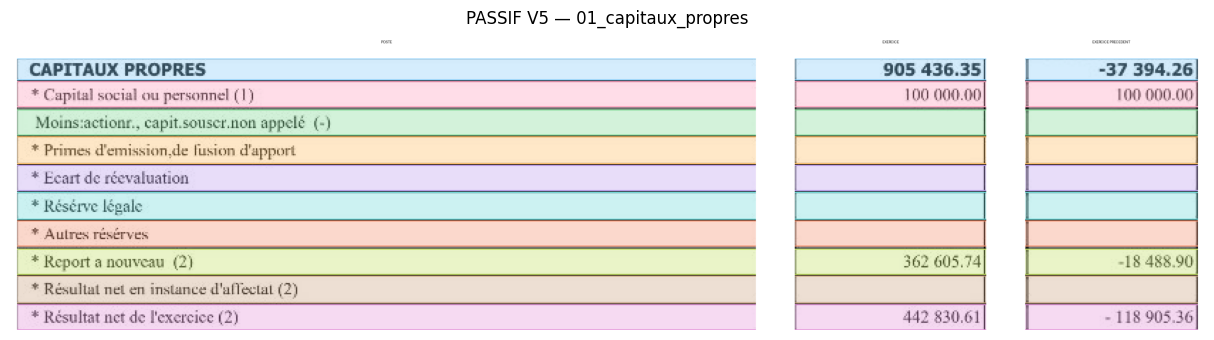

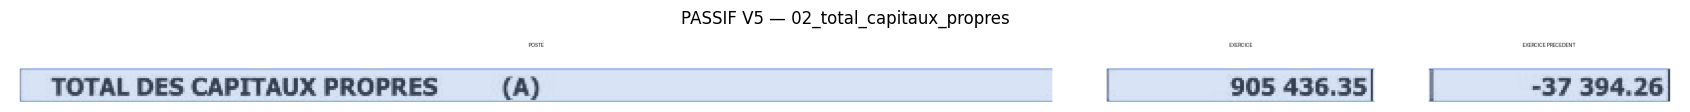

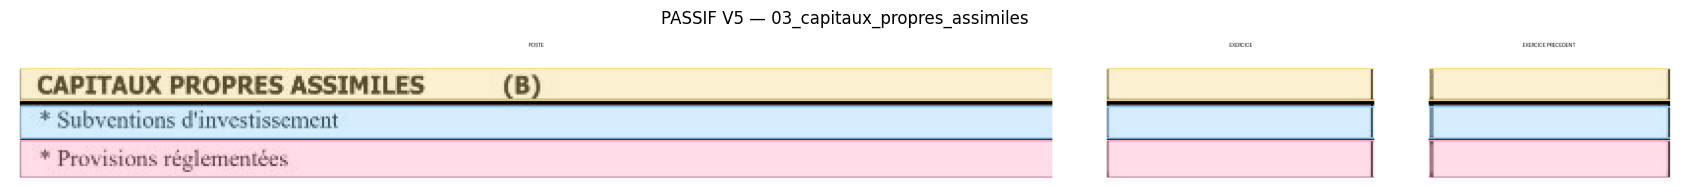

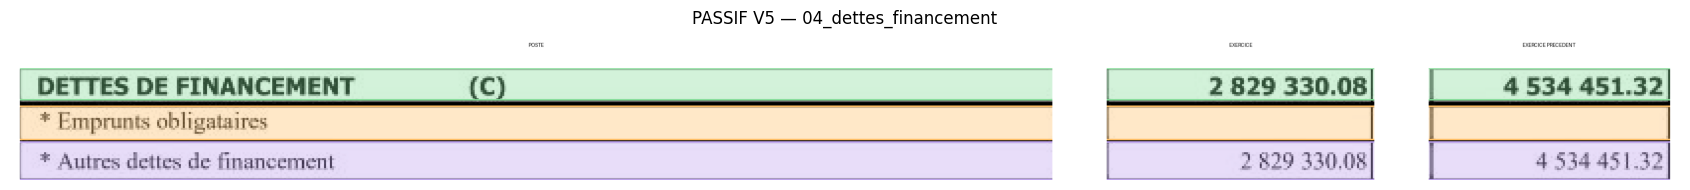

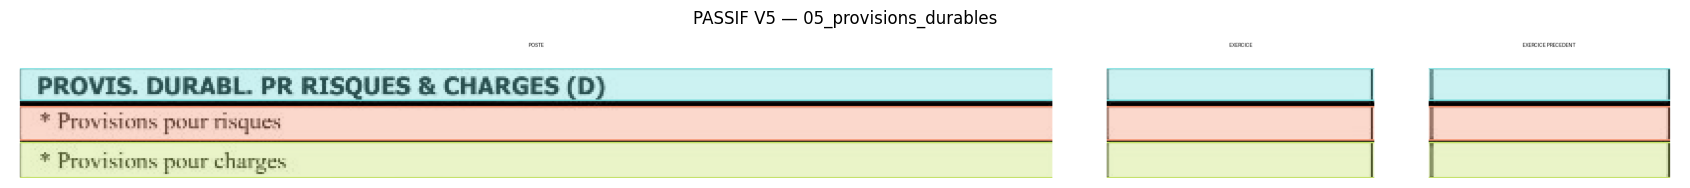

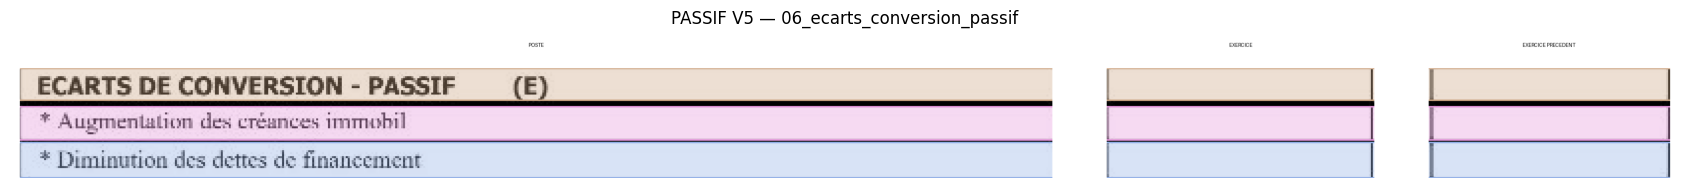

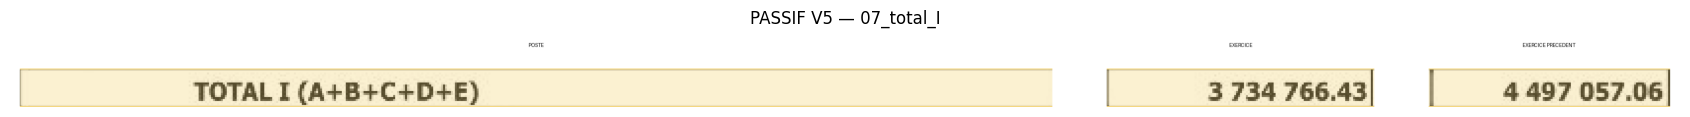

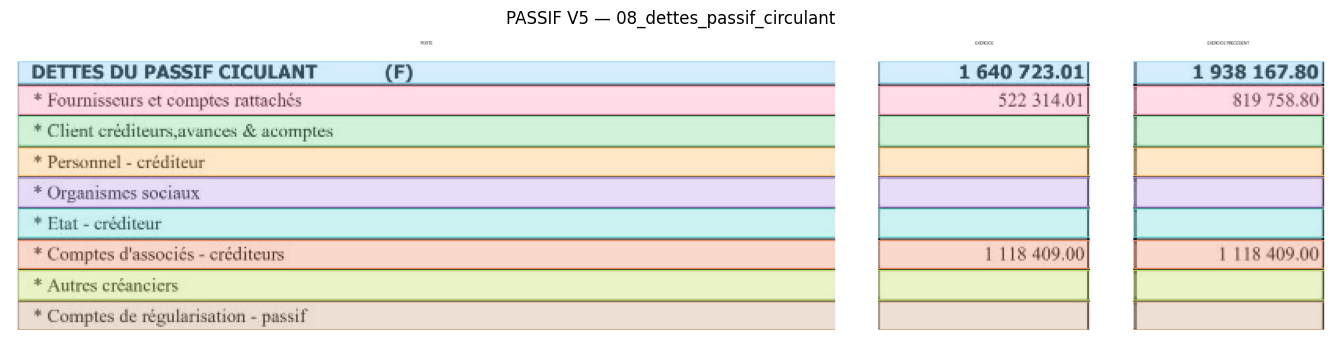

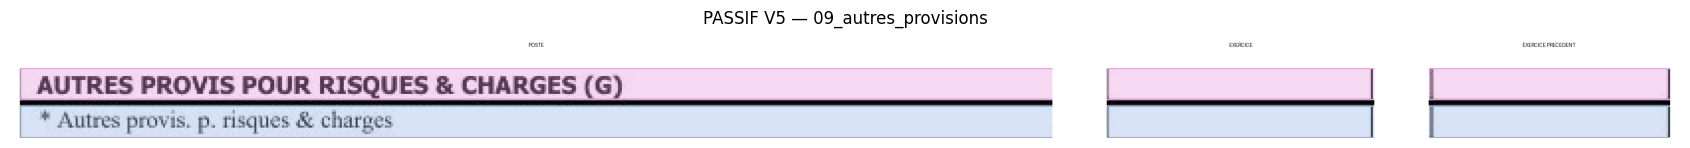

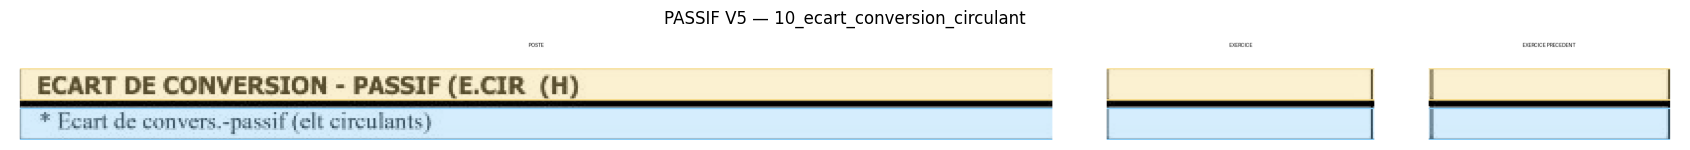

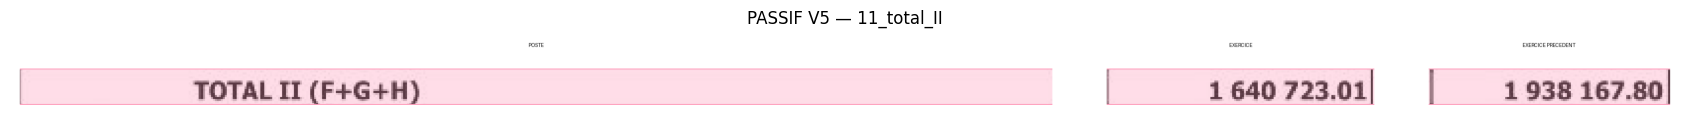

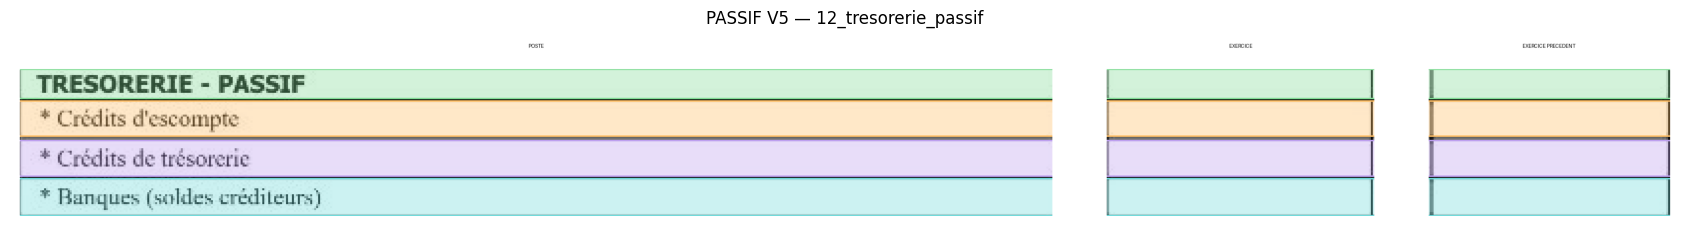

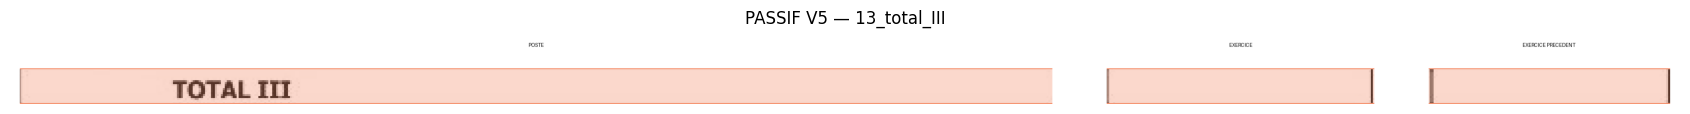

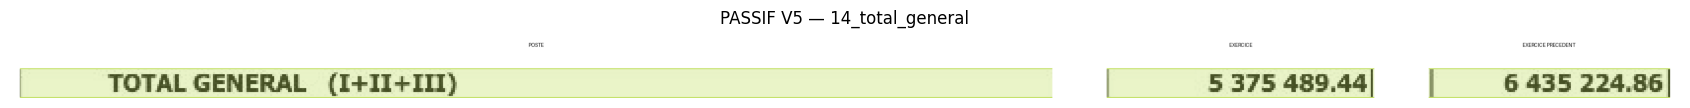

In [41]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw, ImageFont
from pathlib import Path

# ============================================================
# 1. CONFIGURATION
# ============================================================

input_dir = Path(
    "/kaggle/working/groupes_passif_v3"
)

output_dir = Path(
    "/kaggle/working/groupes_passif_v5"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

images_passif = sorted(input_dir.glob("*.png"))

assert len(images_passif) == 14, (
    f"14 images attendues, {len(images_passif)} trouvées"
)

print("Images trouvées :", len(images_passif))

# Paramètres V5
HEADER_H = 75
ESPACE = 110
MARGE = 20

# ============================================================
# 2. DÉTECTION DES SÉPARATEURS VERTICAUX
# ============================================================

def detecter_separateurs(img):

    gray = cv2.cvtColor(
        img[:HEADER_H - 5],
        cv2.COLOR_RGB2GRAY
    )

    # Détecter les lignes noires de l'en-tête
    scores = (gray < 130).sum(axis=0)

    indices = np.where(
        scores > int(gray.shape[0] * 0.75)
    )[0]

    if len(indices) == 0:
        raise ValueError(
            "Aucun séparateur vertical détecté"
        )

    blocs = np.split(
        indices,
        np.where(np.diff(indices) > 1)[0] + 1
    )

    bandes = [
        (int(b[0]), int(b[-1]))
        for b in blocs
        if len(b) > 0
    ]

    largeur = img.shape[1]

    # Ignorer les bordures extérieures
    bandes = [
        (a, b)
        for a, b in bandes
        if a > 20 and b < largeur - 20
    ]

    if len(bandes) != 2:
        raise ValueError(
            f"Deux séparateurs attendus : {bandes}"
        )

    return bandes


# ============================================================
# 3. CONFIGURATION DES NOUVEAUX EN-TÊTES
# ============================================================

titres = [
    "POSTE",
    "EXERCICE",
    "EXERCICE PRECEDENT"
]

try:
    font = ImageFont.truetype(
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf",
        25
    )
except OSError:
    font = ImageFont.load_default()


# ============================================================
# 4. TRAITER AUTOMATIQUEMENT LES 14 IMAGES
# ============================================================

statistiques = []

for index, image_path in enumerate(images_passif, start=1):

    nom = image_path.stem

    print("\n" + "=" * 65)
    print(f"PRÉTRAITEMENT PASSIF V5 — {index}/14")
    print("=" * 65)

    # --------------------------------------------------------
    # CHARGER L'IMAGE V3
    # --------------------------------------------------------

    img = np.array(
        Image.open(image_path).convert("RGB")
    )

    h, w = img.shape[:2]

    print("Image :", image_path.name)
    print("Dimensions V3 :", (w, h))

    # --------------------------------------------------------
    # DÉTECTER LES DEUX SÉPARATEURS
    # --------------------------------------------------------

    (a1, b1), (a2, b2) = detecter_separateurs(img)

    print("Séparateur 1 :", (a1, b1))
    print("Séparateur 2 :", (a2, b2))

    # --------------------------------------------------------
    # RETIRER L'ANCIEN EN-TÊTE ARTIFICIEL
    # --------------------------------------------------------

    corps = img[HEADER_H:]

    # --------------------------------------------------------
    # EXTRAIRE LES TROIS COLONNES
    # --------------------------------------------------------

    # Colonne POSTE
    poste = corps[:, 2:a1]

    # Colonne EXERCICE
    exercice = corps[:, b1 + 1:a2]

    # Colonne EXERCICE PRECEDENT
    precedent = corps[:, b2 + 1:w - 2]

    colonnes = [
        poste,
        exercice,
        precedent
    ]

    assert all(col.shape[1] > 0 for col in colonnes), (
        f"Largeur de colonne invalide : {nom}"
    )

    # --------------------------------------------------------
    # CRÉER UNE IMAGE AVEC ESPACES BLANCS
    # --------------------------------------------------------

    largeur_finale = (
        sum(col.shape[1] for col in colonnes)
        + 2 * ESPACE
        + 2 * MARGE
    )

    hauteur_finale = (
        corps.shape[0] + HEADER_H
    )

    canvas = np.full(
        (hauteur_finale, largeur_finale, 3),
        255,
        dtype=np.uint8
    )

    x = MARGE
    centres = []

    # Replacer les trois colonnes
    for col in colonnes:

        largeur_col = col.shape[1]

        canvas[
            HEADER_H:,
            x:x + largeur_col
        ] = col

        centres.append(
            x + largeur_col // 2
        )

        x += largeur_col + ESPACE

    # --------------------------------------------------------
    # AJOUTER LES NOUVEAUX EN-TÊTES
    # --------------------------------------------------------

    output = Image.fromarray(canvas)

    draw = ImageDraw.Draw(output)

    for titre, centre in zip(titres, centres):

        bbox = draw.textbbox(
            (0, 0),
            titre,
            font=font
        )

        text_w = bbox[2] - bbox[0]

        draw.text(
            (
                centre - text_w // 2,
                22
            ),
            titre,
            fill=(0, 0, 0),
            font=font
        )

    # --------------------------------------------------------
    # ENREGISTRER L'IMAGE V5
    # --------------------------------------------------------

    output_path = output_dir / f"{nom}.png"

    output.save(output_path)

    print("Dimensions V5 :", output.size)
    print("Image sauvegardée :", output_path.name)

    statistiques.append({
        "image": nom,
        "largeur_v3": w,
        "hauteur_v3": h,
        "largeur_v5": output.size[0],
        "hauteur_v5": output.size[1],
        "separateur_1": a1,
        "separateur_2": a2,
        "statut": "TRAITÉE"
    })


# ============================================================
# 5. RÉSUMÉ DES 14 IMAGES
# ============================================================

df_v5 = pd.DataFrame(statistiques)

print("\n" + "=" * 65)
print("RÉSUMÉ DU PRÉTRAITEMENT V5")
print("=" * 65)

display(df_v5)

nb_images = len(
    list(output_dir.glob("*.png"))
)

print("Images V3 :", len(images_passif))
print("Images V5 :", nb_images)

assert nb_images == 14

df_v5.to_csv(
    output_dir / "statistiques_pretraitement_v5.csv",
    index=False
)

print("\n✅ LES 14 IMAGES PASSIF V5 SONT CRÉÉES")
print("Dossier :", output_dir)


# ============================================================
# 6. VISUALISER LES 14 IMAGES V5
# ============================================================

for image_path in sorted(output_dir.glob("*.png")):

    img = Image.open(image_path)

    plt.figure(figsize=(17, 3.5))

    plt.imshow(img)

    plt.title(
        f"PASSIF V5 — {image_path.stem}",
        fontsize=12
    )

    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [49]:
INPUT_DIR = Path(
    "/kaggle/working/groupes_passif_v5"
)

OUTPUT_DIR = Path(
    "/kaggle/working/resultats_qwen7b_passif_v5_v12"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

prompt = create_prompt_passif_v12(
    group_name,
    expected_rows
)

In [50]:
# ============================================================
# BILAN PASSIF MAROCAIN
# INFÉRENCE QWEN2.5-VL-7B-INSTRUCT
# IMAGES V5 + PROMPT V11
# 14 GROUPES - UNE INFÉRENCE PAR IMAGE
# ============================================================

import torch
import json
import re
import time
import gc
import pandas as pd

from pathlib import Path
from PIL import Image
from qwen_vl_utils import process_vision_info

# ============================================================
# 1. CONFIGURATION
# ============================================================

INPUT_DIR = Path(
    "/kaggle/working/groupes_passif_v5"
)

OUTPUT_DIR = Path(
    "/kaggle/working/resultats_qwen7b_passif_v5_v12"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ============================================================
# 2. LES 14 GROUPES DU PASSIF
# ============================================================

GROUPES_PASSIF = {

    "01_capitaux_propres": (
        "CAPITAUX PROPRES", 10
    ),

    "02_total_capitaux_propres": (
        "TOTAL DES CAPITAUX PROPRES (A)", 1
    ),

    "03_capitaux_propres_assimiles": (
        "CAPITAUX PROPRES ASSIMILES (B)", 3
    ),

    "04_dettes_financement": (
        "DETTES DE FINANCEMENT (C)", 3
    ),

    "05_provisions_durables": (
        "PROVIS. DURABL. PR RISQUES & CHARGES (D)", 3
    ),

    "06_ecarts_conversion_passif": (
        "ECARTS DE CONVERSION - PASSIF (E)", 3
    ),

    "07_total_I": (
        "TOTAL I (A+B+C+D+E)", 1
    ),

    "08_dettes_passif_circulant": (
        "DETTES DU PASSIF CIRCULANT (F)", 9
    ),

    "09_autres_provisions": (
        "AUTRES PROVIS POUR RISQUES & CHARGES (G)", 2
    ),

    "10_ecart_conversion_circulant": (
        "ECART DE CONVERSION - PASSIF (E.CIR (H)", 2
    ),

    "11_total_II": (
        "TOTAL II (F+G+H)", 1
    ),

    "12_tresorerie_passif": (
        "TRESORERIE - PASSIF", 4
    ),

    "13_total_III": (
        "TOTAL III", 1
    ),

    "14_total_general": (
        "TOTAL GENERAL (I+II+III)", 1
    )
}

# ============================================================
# 3. VÉRIFICATIONS
# ============================================================

assert "model" in globals(), (
    "Le modèle Qwen 7B n'est pas chargé."
)

assert "processor" in globals(), (
    "Le processeur Qwen n'est pas chargé."
)

assert "create_prompt_passif_v11" in globals(), (
    "Exécute d'abord la cellule du prompt V11."
)

model_name = str(
    getattr(model.config, "_name_or_path", "")
)

assert "7b" in model_name.lower(), (
    f"Modèle incorrect : {model_name}"
)

assert len(GROUPES_PASSIF) == 14

total_attendu = sum(
    nb_lignes
    for _, nb_lignes in GROUPES_PASSIF.values()
)

assert total_attendu == 44

for groupe_id in GROUPES_PASSIF:

    image_path = INPUT_DIR / f"{groupe_id}.png"

    assert image_path.exists(), (
        f"Image manquante : {image_path}"
    )

model.eval()

print("=" * 65)
print("CONFIGURATION DE L'EXPÉRIENCE")
print("=" * 65)

print("Modèle :", model_name)
print("Images :", INPUT_DIR)
print("Prompt : V11")
print("Groupes :", len(GROUPES_PASSIF))
print("Lignes attendues :", total_attendu)
print("GPU :", torch.cuda.get_device_name(0))
print("Dossier des résultats :", OUTPUT_DIR)

# ============================================================
# 4. CHAMPS JSON
# ============================================================

CHAMPS_OBLIGATOIRES = {
    "id_ligne",
    "poste",
    "exercice",
    "exercice_precedent"
}

CHAMPS_NUMERIQUES = [
    "exercice",
    "exercice_precedent"
]

statistiques = []
resultats_json = {}

# ============================================================
# 5. INFÉRENCE SUR LES 14 GROUPES
# ============================================================

for index, (groupe_id, groupe_info) in enumerate(
    GROUPES_PASSIF.items(),
    start=1
):

    group_name, expected_rows = groupe_info

    print("\n" + "=" * 70)
    print(
        f"QWEN 7B + V5 + V11 — GROUPE "
        f"{index}/{len(GROUPES_PASSIF)}"
    )
    print("=" * 70)

    # --------------------------------------------------------
    # 5.1 CHARGEMENT IMAGE
    # --------------------------------------------------------

    image_path = INPUT_DIR / f"{groupe_id}.png"

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    print("Image :", image_path.name)
    print("Groupe :", group_name)
    print("Dimensions :", image.size)
    print("Lignes attendues :", expected_rows)

    # --------------------------------------------------------
    # 5.2 PROMPT V11 UNIVERSEL
    # --------------------------------------------------------

    prompt = create_prompt_passif_v11(
        group_name,
        expected_rows
    )

    # --------------------------------------------------------
    # 5.3 PRÉPARATION DES MESSAGES
    # --------------------------------------------------------

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image
                },
                {
                    "type": "text",
                    "text": prompt
                }
            ]
        }
    ]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(
        messages
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    print(
        "Grille visuelle :",
        inputs.image_grid_thw[0].tolist()
    )

    # ========================================================
    # 6. INFÉRENCE QWEN 7B
    # ========================================================

    start = time.perf_counter()

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=2048,
            do_sample=False
        )

    elapsed = time.perf_counter() - start

    # --------------------------------------------------------
    # 6.1 DÉCODAGE
    # --------------------------------------------------------

    trimmed_ids = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(
            inputs.input_ids,
            generated_ids
        )
    ]

    response = processor.batch_decode(
        trimmed_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]

    print("\n===== RÉSULTAT BRUT =====")
    print(response)

    print(
        "\nTemps d'inférence :",
        round(elapsed, 2),
        "secondes"
    )

    # ========================================================
    # 7. SAUVEGARDE DE LA RÉPONSE BRUTE
    # ========================================================

    raw_path = OUTPUT_DIR / f"{groupe_id}.txt"

    raw_path.write_text(
        response,
        encoding="utf-8"
    )

    # Retirer uniquement les balises Markdown éventuelles
    # Aucune modification des montants ou libellés.

    clean_response = re.sub(
        r"^```(?:json)?\s*|\s*```$",
        "",
        response.strip(),
        flags=re.IGNORECASE
    ).strip()

    json_path = OUTPUT_DIR / f"{groupe_id}.json"

    if json_path.exists():
        json_path.unlink()

    # ========================================================
    # 8. VALIDATION AUTOMATIQUE
    # ========================================================

    erreurs = []

    nb_lignes = 0
    nb_montants = 0
    nb_cellules_vides = 0

    titre_correct = False
    data = None

    try:

        data = json.loads(clean_response)

        if not isinstance(data, dict):
            raise ValueError(
                "Le JSON principal n'est pas un objet"
            )

        lignes = data.get("lignes")

        if not isinstance(lignes, list):
            raise ValueError(
                "Le champ lignes n'est pas une liste"
            )

        nb_lignes = len(lignes)

        # ----------------------------------------------------
        # 8.1 NOM DU GROUPE
        # ----------------------------------------------------

        if data.get("groupe") != group_name:

            erreurs.append(
                "Nom du groupe incorrect"
            )

        # ----------------------------------------------------
        # 8.2 NOMBRE DE LIGNES
        # ----------------------------------------------------

        if nb_lignes != expected_rows:

            erreurs.append(
                f"Nombre de lignes : "
                f"{nb_lignes}/{expected_rows}"
            )

        # ----------------------------------------------------
        # 8.3 TITRE PRINCIPAL
        # ----------------------------------------------------

        if lignes and isinstance(lignes[0], dict):

            titre_correct = (
                lignes[0].get("poste") == group_name
            )

        if not titre_correct:

            erreurs.append(
                "Titre principal incorrect"
            )

        # ----------------------------------------------------
        # 8.4 VÉRIFICATION DE CHAQUE LIGNE
        # ----------------------------------------------------

        for i, ligne in enumerate(lignes, start=1):

            if not isinstance(ligne, dict):

                erreurs.append(
                    f"Ligne {i} : objet invalide"
                )

                continue

            # Vérification des champs
            if set(ligne.keys()) != CHAMPS_OBLIGATOIRES:

                erreurs.append(
                    f"Ligne {i} : champs JSON incorrects"
                )

            # Vérification ID
            if ligne.get("id_ligne") != i:

                erreurs.append(
                    f"Ligne {i} : identifiant incorrect"
                )

            # Vérification libellé
            poste = ligne.get("poste")

            if (
                not isinstance(poste, str)
                or not poste.strip()
            ):

                erreurs.append(
                    f"Ligne {i} : libellé absent"
                )

            # ------------------------------------------------
            # 8.5 VÉRIFICATION DES MONTANTS
            # ------------------------------------------------

            for champ in CHAMPS_NUMERIQUES:

                if champ not in ligne:

                    continue

                valeur = ligne[champ]

                if valeur is None:

                    nb_cellules_vides += 1
                    continue

                if not isinstance(valeur, str):

                    erreurs.append(
                        f"Ligne {i} : {champ} "
                        "n'est pas une chaîne JSON"
                    )

                    continue

                if not valeur.strip():

                    erreurs.append(
                        f"Ligne {i} : {champ} "
                        "contient une chaîne vide"
                    )

                    continue

                nb_montants += 1

        # ----------------------------------------------------
        # 8.6 VÉRIFICATION DES TITRES RÉPÉTÉS
        # ----------------------------------------------------

        if len(lignes) >= 2:

            ligne1 = lignes[0]
            ligne2 = lignes[1]

            if (
                isinstance(ligne1, dict)
                and isinstance(ligne2, dict)
                and isinstance(ligne1.get("poste"), str)
                and isinstance(ligne2.get("poste"), str)
            ):

                if (
                    ligne1["poste"].strip().casefold()
                    == ligne2["poste"].strip().casefold()
                ):

                    erreurs.append(
                        "Titre principal répété à la ligne 2"
                    )

        # ----------------------------------------------------
        # 8.7 SAUVEGARDE JSON SANS CORRECTION
        # ----------------------------------------------------

        with open(
            json_path,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                data,
                f,
                ensure_ascii=False,
                indent=2
            )

        resultats_json[groupe_id] = data

        statut = (
            "STRUCTURE CONFORME"
            if not erreurs
            else "À VÉRIFIER"
        )

    except (json.JSONDecodeError, ValueError) as e:

        erreurs.append(str(e))

        statut = "JSON INVALIDE"

    # ========================================================
    # 9. DIAGNOSTIC DU GROUPE
    # ========================================================

    print("\n===== DIAGNOSTIC =====")

    print("Groupe :", group_name)

    print(
        "Lignes extraites :",
        nb_lignes,
        "/",
        expected_rows
    )

    print("Titre principal correct :", titre_correct)

    print("Montants non vides :", nb_montants)

    print("Cellules numériques null :", nb_cellules_vides)

    print("Statut :", statut)

    if erreurs:

        for erreur in erreurs:

            print("❌", erreur)

    else:

        print("✅ Aucun problème structurel détecté")

    # --------------------------------------------------------
    # 9.1 STATISTIQUES
    # --------------------------------------------------------

    statistiques.append({
        "id_groupe": groupe_id,
        "groupe": group_name,
        "lignes_attendues": expected_rows,
        "lignes_extraites": nb_lignes,
        "titre_correct": titre_correct,
        "montants_non_vides": nb_montants,
        "cellules_null": nb_cellules_vides,
        "statut": statut,
        "nb_erreurs": len(erreurs),
        "details_erreurs": " | ".join(erreurs),
        "temps_secondes": round(elapsed, 2)
    })

    # ========================================================
    # 10. LIBÉRER LA MÉMOIRE TEMPORAIRE
    # ========================================================

    del inputs
    del generated_ids
    del trimmed_ids
    del image_inputs
    del video_inputs

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

# ============================================================
# 11. TABLEAU RÉCAPITULATIF
# ============================================================

df_v11 = pd.DataFrame(statistiques)

print("\n" + "=" * 70)
print("RÉSUMÉ GLOBAL — QWEN 7B + V5 + V11")
print("=" * 70)

display(df_v11)

total_extrait = int(
    df_v11["lignes_extraites"].sum()
)

total_montants = int(
    df_v11["montants_non_vides"].sum()
)

total_null = int(
    df_v11["cellules_null"].sum()
)

nb_conformes = int(
    (
        df_v11["statut"] == "STRUCTURE CONFORME"
    ).sum()
)

print("\nGroupes testés :", len(statistiques))

print(
    "Structures conformes :",
    nb_conformes,
    "/14"
)

print(
    "Lignes extraites :",
    total_extrait,
    "/44"
)

print(
    "Montants non vides extraits :",
    total_montants
)

print(
    "Cellules numériques null :",
    total_null
)

print(
    "Temps total :",
    round(
        df_v11["temps_secondes"].sum(),
        2
    ),
    "secondes"
)

# ============================================================
# 12. SAUVEGARDE DES STATISTIQUES
# ============================================================

stats_path = (
    OUTPUT_DIR / "statistiques_passif_v5_v11.csv"
)

df_v11.to_csv(
    stats_path,
    index=False,
    encoding="utf-8-sig"
)

# ============================================================
# 13. FUSION DES JSON DANS L'ORDRE
# ============================================================

groupes_ordonnes = [
    resultats_json[groupe_id]
    for groupe_id in GROUPES_PASSIF
    if groupe_id in resultats_json
]

bilan_final = {
    "document": "Bilan Passif",
    "modele": "Qwen2.5-VL-7B-Instruct",
    "pretraitement": "V5 - Colonnes espacées",
    "prompt": "V11",
    "groupes": groupes_ordonnes
}

final_path = (
    OUTPUT_DIR / "bilan_passif_7b_v5_v11.json"
)

with open(
    final_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        bilan_final,
        f,
        ensure_ascii=False,
        indent=2
    )

# ============================================================
# 14. VÉRIFICATION DES DEUX TOTAUX
# ============================================================

# Valeurs de référence utilisées uniquement APRÈS
# les inférences pour l'évaluation.
# Elles ne sont jamais envoyées au modèle.

references_totaux = {
    "07_total_I": {
        "exercice": "3 734 766.43",
        "exercice_precedent": "4 497 057.06"
    },
    "14_total_general": {
        "exercice": "5 375 489.44",
        "exercice_precedent": "6 435 224.86"
    }
}

print("\n===== VÉRIFICATION DES DEUX TOTAUX =====")

for groupe_id, reference in references_totaux.items():

    if groupe_id not in resultats_json:

        print("❌ Groupe absent :", groupe_id)
        continue

    lignes = resultats_json[groupe_id].get("lignes", [])

    if not lignes or not isinstance(lignes[0], dict):

        print("❌ Première ligne invalide :", groupe_id)
        continue

    ligne = lignes[0]

    print("\nGroupe :", groupe_id)

    for champ, attendu in reference.items():

        extrait = ligne.get(champ)

        correct = extrait == attendu

        print(
            "✅" if correct else "❌",
            champ,
            "| extrait :", extrait,
            "| attendu :", attendu
        )

# ============================================================
# 15. FIN
# ============================================================

print("\n" + "=" * 70)
print("EXTRACTION PASSIF TERMINÉE")
print("=" * 70)

print("Modèle :", model_name)
print("Images : V5")
print("Prompt : V11")
print("Groupes sauvegardés :", len(groupes_ordonnes))

print("\nJSON final :", final_path)
print("Statistiques :", stats_path)
print("Dossier :", OUTPUT_DIR)

CONFIGURATION DE L'EXPÉRIENCE
Modèle : Qwen/Qwen2.5-VL-7B-Instruct
Images : /kaggle/working/groupes_passif_v5
Prompt : V12
Groupes : 14
Lignes attendues : 44
GPU : Tesla T4
Résultats : /kaggle/working/resultats_qwen7b_passif_v5_v12

PASSIF V5 + PROMPT V12 — GROUPE 1/14
Image : 01_capitaux_propres.png
Groupe : CAPITAUX PROPRES
Dimensions : (3382, 843)
Lignes attendues : 10
Grille visuelle : [1, 34, 142]

===== RÉSULTAT BRUT =====
```json
{
    "groupe": "CAPITAUX PROPRES",
    "lignes": [
        {
            "id_ligne": 1,
            "poste": "CAPITAUX PROPRES",
            "exercice": "905 436.35",
            "exercice_precedent": "-37 394.26"
        },
        {
            "id_ligne": 2,
            "poste": "Capital social ou personnel (1)",
            "exercice": "100 000.00",
            "exercice_precedent": "100 000.00"
        },
        {
            "id_ligne": 3,
            "poste": "Moins:actionr., capit.souscr.non appelé (-)",
            "exercice": null,
         

,id_groupe,groupe,lignes_attendues,lignes_extraites,titre_correct,montants_non_vides,cellules_null,statut,nb_erreurs,details_erreurs,temps_secondes
0,01_capitaux_propres,CAPITAUX PROPRES,10,10,True,8,12,STRUCTURE CONFORME,0,,106.37
1,02_total_capitaux_propres,TOTAL DES CAPITAUX PROPRES (A),1,1,True,2,0,STRUCTURE CONFORME,0,,33.52
2,03_capitaux_propres_assimiles,CAPITAUX PROPRES ASSIMILES (B),3,3,True,0,6,STRUCTURE CONFORME,0,,50.02
3,04_dettes_financement,DETTES DE FINANCEMENT (C),3,3,True,2,4,STRUCTURE CONFORME,0,,52.68
4,05_provisions_durables,PROVIS. DURABL. PR RISQUES & CHARGES (D),3,3,True,0,6,STRUCTURE CONFORME,0,,51.97
5,06_ecarts_conversion_passif,ECARTS DE CONVERSION - PASSIF (E),3,3,True,0,6,STRUCTURE CONFORME,0,,50.68
6,07_total_I,TOTAL I (A+B+C+D+E),1,1,True,2,0,STRUCTURE CONFORME,0,,33.90
7,08_dettes_passif_circulant,DETTES DU PASSIF CIRCULANT (F),9,9,True,6,12,STRUCTURE CONFORME,0,,99.14
8,09_autres_provisions,AUTRES PROVIS POUR RISQUES & CHARGES (G),2,2,True,0,4,STRUCTURE CONFORME,0,,43.76
9,10_ecart_conversion_circulant,ECART DE CONVERSION - PASSIF (E.CIR (H),2,2,True,0,4,STRUCTURE CONFORME,0,,43.24



Groupes : 14
Groupes conformes : 14 /14
Lignes extraites : 44 /44
Montants non vides : 24
Cellules null : 64
Temps total : 717.92 secondes

===== ÉVALUATION DES DEUX TOTAUX =====

Groupe : 07_total_I
✅ exercice | extrait : 3 734 766.43 | attendu : 3 734 766.43
✅ exercice_precedent | extrait : 4 497 057.06 | attendu : 4 497 057.06

Groupe : 14_total_general
✅ exercice | extrait : 5 375 489.44 | attendu : 5 375 489.44
✅ exercice_precedent | extrait : 6 435 224.86 | attendu : 6 435 224.86

EXTRACTION PASSIF V5 + V12 TERMINÉE
Modèle : Qwen/Qwen2.5-VL-7B-Instruct
Images : V5
Prompt : V12
Groupes sauvegardés : 14

JSON final : /kaggle/working/resultats_qwen7b_passif_v5_v12/bilan_passif_7b_v5_v12.json
Statistiques : /kaggle/working/resultats_qwen7b_passif_v5_v12/statistiques_passif_v5_v12.csv
Dossier : /kaggle/working/resultats_qwen7b_passif_v5_v12

✅ Toutes les structures sont conformes


In [52]:
# ============================================================
# PROJET VLM — EXTRACTION BILAN PASSIF MAROCAIN
#
# MODÈLE        : Qwen2.5-VL-7B-Instruct
# PRÉTRAITEMENT : Images V5 (colonnes espacées)
# PROMPT        : V13 universel
# GROUPES       : 14
# LIGNES        : 44
#
# UNE SEULE INFÉRENCE PAR IMAGE
# MÊME PROMPT POUR TOUS LES GROUPES
# AUCUNE CORRECTION MANUELLE DES JSON
# ============================================================

import os
import re
import gc
import json
import time
import torch
import pandas as pd

from pathlib import Path
from PIL import Image
from qwen_vl_utils import process_vision_info


# ============================================================
# 1. CONFIGURATION
# ============================================================

INPUT_DIR = Path(
    "/kaggle/working/groupes_passif_v5"
)

OUTPUT_DIR = Path(
    "/kaggle/working/resultats_qwen7b_passif_v5_v13"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ID = "Qwen/Qwen2.5-VL-7B-Instruct"

assert torch.cuda.is_available(), (
    "Active le GPU dans les paramètres Kaggle."
)


# ============================================================
# 2. GROUPES PASSIF
# ============================================================

GROUPES_PASSIF = {

    "01_capitaux_propres": (
        "CAPITAUX PROPRES", 10
    ),

    "02_total_capitaux_propres": (
        "TOTAL DES CAPITAUX PROPRES (A)", 1
    ),

    "03_capitaux_propres_assimiles": (
        "CAPITAUX PROPRES ASSIMILES (B)", 3
    ),

    "04_dettes_financement": (
        "DETTES DE FINANCEMENT (C)", 3
    ),

    "05_provisions_durables": (
        "PROVIS. DURABL. PR RISQUES & CHARGES (D)", 3
    ),

    "06_ecarts_conversion_passif": (
        "ECARTS DE CONVERSION - PASSIF (E)", 3
    ),

    "07_total_I": (
        "TOTAL I (A+B+C+D+E)", 1
    ),

    "08_dettes_passif_circulant": (
        "DETTES DU PASSIF CIRCULANT (F)", 9
    ),

    "09_autres_provisions": (
        "AUTRES PROVIS POUR RISQUES & CHARGES (G)", 2
    ),

    "10_ecart_conversion_circulant": (
        "ECART DE CONVERSION - PASSIF (E.CIR (H)", 2
    ),

    "11_total_II": (
        "TOTAL II (F+G+H)", 1
    ),

    "12_tresorerie_passif": (
        "TRESORERIE - PASSIF", 4
    ),

    "13_total_III": (
        "TOTAL III", 1
    ),

    "14_total_general": (
        "TOTAL GENERAL (I+II+III)", 1
    )
}


# ============================================================
# 3. PROMPT V13 UNIVERSEL
# BASÉ SUR V12 + RÈGLE DES MONTANTS RÉPÉTÉS
# ============================================================

def create_prompt_passif_v13(group_name, expected_rows):

    return f"""
Tu es un expert en extraction de tableaux financiers
marocains et en reconnaissance visuelle OCR.

DOCUMENT : BILAN PASSIF MAROCAIN.

NOM EXACT DU GROUPE : {group_name}
NOMBRE EXACT DE LIGNES : {expected_rows}

MISSION :
Transformer chaque bande horizontale colorée en
un objet JSON, sans perdre aucune ligne.

C'est une transcription visuelle OCR.
Ce n'est PAS un exercice de comptabilité.

Tous les montants doivent être lus dans l'image.

==================================================
RÈGLE N°1 — TITRE PRINCIPAL OBLIGATOIRE
==================================================

LE TITRE DU GROUPE EST UNE LIGNE FINANCIÈRE.

Le groupe contient EXACTEMENT {expected_rows} lignes :

- UNE ligne principale.
- {expected_rows - 1} autres lignes financières.

Le premier objet de "lignes" DOIT contenir :

id_ligne = 1
poste = "{group_name}"

Le nom "{group_name}" est fourni comme métadonnée.

Tu dois utiliser cette métadonnée uniquement
pour le poste du PREMIER objet JSON.

Le titre doit apparaître DEUX FOIS :

1. Dans le champ "groupe".
2. Dans le champ "poste" de la première ligne.

Ne commence jamais directement par une sous-ligne.

Même si le titre ne possède AUCUN montant,
il doit être présent en première ligne.

==================================================
RÈGLE N°2 — PREMIÈRE BANDE COLORÉE
==================================================

La première bande colorée sous l'en-tête
correspond à la ligne principale du groupe.

Tu dois :

1. Créer l'objet id_ligne = 1.
2. Mettre poste = "{group_name}".
3. Lire les DEUX cellules numériques de cette bande.
4. Retourner null pour les cellules vides.

Les deux cellules numériques sont :

exercice
exercice_precedent

Même si les deux cellules sont vides,
conserve la ligne principale.

Ne l'ignore jamais parce qu'elle est en gras,
en majuscules ou parce qu'elle ressemble
à un titre.

Un titre financier n'est PAS un en-tête artificiel.

==================================================
RÈGLE N°3 — TOUTES LES LIGNES FINANCIÈRES
==================================================

Après la première bande, extrais les
{expected_rows - 1} autres bandes financières.

Chaque bande colorée = UN objet JSON.

Lis toutes les bandes de haut en bas.

Les identifiants vont de 1 à {expected_rows}.

Ne saute aucune ligne.

Une ligne sans montant reste une ligne financière.

Pour les sous-lignes :

- Lis directement le libellé dans l'image.
- Conserve les abréviations.
- Conserve les astérisques.
- Conserve les signes et parenthèses.
- Ne copie pas le titre principal.
- Ne copie pas le libellé d'une autre bande.
- N'invente aucun libellé.

Si un libellé est illisible, retourne null
pour "poste", mais conserve la ligne.

Ne fusionne aucune ligne.
Ne supprime aucune ligne.
Ne décale aucun identifiant.

==================================================
RÈGLE N°4 — STRUCTURE DES IMAGES V5
==================================================

L'image a été prétraitée avec OpenCV.

Les colonnes sont séparées par des espaces blancs.

Il existe EXACTEMENT trois colonnes :

POSTE | EXERCICE | EXERCICE PRECEDENT

Correspondance JSON :

POSTE = poste
EXERCICE = exercice
EXERCICE PRECEDENT = exercice_precedent

IL EXISTE UNIQUEMENT DEUX COLONNES NUMÉRIQUES.

Les en-têtes artificiels ajoutés au-dessus
des bandes financières doivent être ignorés.

Les titres financiers colorés sont des données
et doivent être extraits.

Les montants d'une même bande sont associés
au même poste financier.

Chaque montant doit rester dans sa colonne.

Ne décale pas les valeurs.

Ne confonds pas un espace blanc séparant
les colonnes avec une cellule numérique vide.

==================================================
RÈGLE N°5 — CELLULES VIDES
==================================================

CERTAINS GROUPES SONT ENTIÈREMENT VIDES
DANS LEURS COLONNES NUMÉRIQUES.

C'EST NORMAL.

UNE LIGNE SANS MONTANT RESTE UNE LIGNE FINANCIÈRE.

Chaque objet JSON doit posséder EXACTEMENT :

"id_ligne"
"poste"
"exercice"
"exercice_precedent"

Si une cellule numérique ne contient
aucun montant visible, retourne null.

Ne retourne JAMAIS :

- ""
- " "
- Un zéro inventé
- Une valeur calculée
- Une valeur copiée d'une autre ligne

Même si TOUTES les cellules numériques
du groupe sont vides, retourne les
{expected_rows} lignes.

IMPORTANT :

Si un groupe contient un titre et deux sous-lignes,
retourne TROIS objets JSON.

Ne retourne jamais uniquement les sous-lignes.

==================================================
RÈGLE N°6 — LECTURE DES MONTANTS
==================================================

Lis les deux colonnes indépendamment :

1. EXERCICE
2. EXERCICE PRECEDENT

Chaque montant provient exclusivement
de sa propre cellule dans l'image.

EXERCICE PRECEDENT contient le montant
réellement imprimé pour l'exercice précédent.

CE N'EST PAS UNE VARIATION.

Ne soustrais jamais les deux montants.

Ne calcule aucune différence.

Ne calcule aucune somme.

Ne calcule aucun total.

Même pour une ligne TOTAL, recopie uniquement
le nombre réellement imprimé.

Conserve :

- Les chiffres visibles.
- Les séparateurs de milliers.
- Les décimales.
- Les signes réellement imprimés.

Ne calcule rien.
Ne corrige rien.
N'invente rien.

==================================================
RÈGLE N°7 — SIGNES NÉGATIFS
==================================================

Un montant est négatif UNIQUEMENT si un vrai
caractère moins (-) est imprimé devant ses chiffres.

Si aucun signe moins n'est visible,
ne retourne pas de signe négatif.

Ne confonds pas les bordures, les séparations
et les traits d'impression avec un signe moins.

Ne déduis jamais le signe par un calcul.

Ne déduis jamais le signe d'une autre cellule.

Conserve les vrais signes négatifs visibles.

==================================================
RÈGLE N°8 — MONTANTS IDENTIQUES ENTRE LIGNES
==================================================

ATTENTION :

Plusieurs lignes financières différentes
peuvent contenir exactement les mêmes
montants imprimés.

C'EST NORMAL.

Chaque bande doit être lue indépendamment.

Si un montant est réellement visible dans
une cellule, recopie-le, même s'il apparaît
déjà dans une autre ligne.

Deux montants identiques imprimés sur
deux bandes différentes représentent
deux occurrences distinctes.

NE SUPPRIME JAMAIS UN MONTANT VISIBLE
UNIQUEMENT PARCE QU'IL EST RÉPÉTÉ.

NE REMPLACE PAS UN MONTANT VISIBLE PAR null
PARCE QU'IL APPARAÎT DÉJÀ AILLEURS.

IMPORTANT :

Cette règle n'autorise pas à copier
automatiquement un montant d'une autre ligne.

Tu dois constater visuellement chaque occurrence
dans sa propre cellule.

Si la cellule est réellement vide,
retourne null, même si une autre ligne
contient un montant identique.

Ne calcule rien.
Ne complète rien.
Ne déduis rien.

==================================================
RÈGLE N°9 — VÉRIFICATION FINALE
==================================================

AVANT DE RÉPONDRE, VÉRIFIE :

1. Le champ "groupe" vaut "{group_name}".

2. Le premier objet possède id_ligne = 1.

3. Le premier objet possède :
   poste = "{group_name}".

4. La première ligne contient les deux champs :
   exercice et exercice_precedent.

5. La liste possède EXACTEMENT
   {expected_rows} objets.

6. Les identifiants vont de 1 à {expected_rows}.

7. Toutes les bandes financières sont présentes.

8. Chaque objet possède exactement quatre champs.

9. Les cellules vides sont null, jamais "".

10. Aucun montant visible n'a été oublié.

11. Les montants répétés visibles sont conservés.

12. Aucun montant n'a été copié automatiquement.

13. EXERCICE PRECEDENT n'est jamais calculé.

14. Aucun signe négatif n'est inventé.

15. Tous les montants proviennent de l'image.

Si le premier objet est absent,
la réponse est INCOMPLÈTE.

Si le nombre de lignes est différent de
{expected_rows}, la réponse est INCOMPLÈTE.

==================================================
RÈGLE N°10 — FORMAT DES MONTANTS OBLIGATOIRE
==================================================

TOUS LES MONTANTS NON VIDES DOIVENT ÊTRE
DES CHAÎNES DE CARACTÈRES JSON.

Chaque montant doit être placé entre
GUILLEMETS DOUBLES.

EXEMPLES DE FORMAT :

CORRECT :
"exercice": "100 000.00"
"exercice_precedent": "-37 394.26"

INCORRECT :
"exercice": 100000.00
"exercice_precedent": -37394.26

Conserve les espaces de milliers
et les deux chiffres décimaux visibles.

N'utilise JAMAIS un nombre JSON
pour un montant financier.

Si une cellule est vide, utilise null
sans guillemets.

RÈGLE STRICTE :

Montant visible = chaîne JSON.
Cellule vide = null.

==================================================
FORMAT JSON FINAL
==================================================

Retourne un unique objet JSON valide :

{{
    "groupe": "{group_name}",
    "lignes": [
        {{
            "id_ligne": 1,
            "poste": "{group_name}",
            "exercice": null,
            "exercice_precedent": null
        }}
    ]
}}

Ceci est uniquement un EXEMPLE de structure.

Remplace les null par les valeurs visibles.

Ajoute toutes les autres bandes jusqu'à
obtenir {expected_rows} lignes.

PRIORITÉ ABSOLUE :

LE PREMIER OBJET CONTIENT LE TITRE DU GROUPE.

AUCUNE LIGNE FINANCIÈRE NE DOIT ÊTRE OUBLIÉE.

AUCUN MONTANT VISIBLE NE DOIT ÊTRE OUBLIÉ.

AUCUN MONTANT NE DOIT ÊTRE INVENTÉ OU CALCULÉ.

Réponds exclusivement avec le JSON complet.

PAS de Markdown.
PAS d'explication.
PAS de commentaire.
"""


# ============================================================
# 4. CHARGEMENT DU MODÈLE SI NÉCESSAIRE
# ============================================================

if "model" not in globals() or "processor" not in globals():

    print("Chargement de Qwen2.5-VL-7B-Instruct...")

    from transformers import (
        Qwen2_5_VLForConditionalGeneration,
        AutoProcessor,
        BitsAndBytesConfig
    )

    quantization_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_compute_dtype=torch.float16,
        bnb_4bit_use_double_quant=True
    )

    model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
        MODEL_ID,
        quantization_config=quantization_config,
        device_map="auto",
        dtype=torch.float16,
        attn_implementation="sdpa"
    )

    processor = AutoProcessor.from_pretrained(
        MODEL_ID,
        min_pixels=256 * 28 * 28,
        max_pixels=1280 * 28 * 28
    )

else:
    print("Modèle et processor déjà chargés.")

model.eval()

model_name = str(
    getattr(model.config, "_name_or_path", "")
)

assert "7b" in model_name.lower(), (
    f"Le modèle chargé n'est pas Qwen 7B : {model_name}"
)


# ============================================================
# 5. VÉRIFICATION DES IMAGES
# ============================================================

assert len(GROUPES_PASSIF) == 14

total_attendu = sum(
    nombre
    for _, nombre in GROUPES_PASSIF.values()
)

assert total_attendu == 44

for groupe_id in GROUPES_PASSIF:

    path = INPUT_DIR / f"{groupe_id}.png"

    assert path.exists(), (
        f"Image manquante : {path}"
    )

print("\n" + "=" * 65)
print("CONFIGURATION DE L'EXPÉRIENCE V13")
print("=" * 65)

print("Modèle :", model_name)
print("Images :", INPUT_DIR)
print("Prompt : V13")
print("Groupes :", len(GROUPES_PASSIF))
print("Lignes attendues :", total_attendu)
print("GPU :", torch.cuda.get_device_name(0))
print("Résultats :", OUTPUT_DIR)


# ============================================================
# 6. CONFIGURATION DE LA VALIDATION
# ============================================================

CHAMPS_OBLIGATOIRES = {
    "id_ligne",
    "poste",
    "exercice",
    "exercice_precedent"
}

CHAMPS_NUMERIQUES = [
    "exercice",
    "exercice_precedent"
]

statistiques = []

resultats_json = {}


# ============================================================
# 7. INFÉRENCE SUR LES 14 GROUPES
# ============================================================

for index, (groupe_id, groupe_info) in enumerate(
    GROUPES_PASSIF.items(),
    start=1
):

    group_name, expected_rows = groupe_info

    print("\n" + "=" * 70)
    print(f"QWEN 7B + V5 + V13 — GROUPE {index}/14")
    print("=" * 70)

    # --------------------------------------------------------
    # IMAGE V5
    # --------------------------------------------------------

    image_path = INPUT_DIR / f"{groupe_id}.png"

    with Image.open(image_path) as img:
        image = img.convert("RGB")

    print("Image :", image_path.name)
    print("Groupe :", group_name)
    print("Dimensions :", image.size)
    print("Lignes attendues :", expected_rows)

    # --------------------------------------------------------
    # MÊME PROMPT V13 POUR TOUS LES GROUPES
    # --------------------------------------------------------

    prompt = create_prompt_passif_v13(
        group_name,
        expected_rows
    )

    # --------------------------------------------------------
    # PRÉPARATION QWEN
    # --------------------------------------------------------

    messages = [{
        "role": "user",
        "content": [
            {
                "type": "image",
                "image": image
            },
            {
                "type": "text",
                "text": prompt
            }
        ]
    }]

    text = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    image_inputs, video_inputs = process_vision_info(
        messages
    )

    inputs = processor(
        text=[text],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors="pt"
    ).to(model.device)

    if "image_grid_thw" in inputs:
        print(
            "Grille visuelle :",
            inputs.image_grid_thw[0].tolist()
        )

    # ========================================================
    # 8. UNE SEULE INFÉRENCE PAR IMAGE
    # ========================================================

    start = time.perf_counter()

    with torch.inference_mode():

        generated_ids = model.generate(
            **inputs,
            max_new_tokens=2048,
            do_sample=False
        )

    elapsed = time.perf_counter() - start

    # --------------------------------------------------------
    # DÉCODAGE
    # --------------------------------------------------------

    trimmed_ids = [
        output_ids[len(input_ids):]
        for input_ids, output_ids in zip(
            inputs.input_ids,
            generated_ids
        )
    ]

    response = processor.batch_decode(
        trimmed_ids,
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False
    )[0]

    print("\n===== RÉSULTAT BRUT =====")
    print(response)

    print(
        "\nTemps d'inférence :",
        round(elapsed, 2),
        "secondes"
    )

    # ========================================================
    # 9. SAUVEGARDE DE LA RÉPONSE ORIGINALE
    # ========================================================

    raw_path = OUTPUT_DIR / f"{groupe_id}.txt"

    raw_path.write_text(
        response,
        encoding="utf-8"
    )

    # Retirer uniquement les balises Markdown.
    # Aucune modification des montants.

    clean_response = re.sub(
        r"^```(?:json)?\s*|\s*```$",
        "",
        response.strip(),
        flags=re.IGNORECASE
    ).strip()

    json_path = OUTPUT_DIR / f"{groupe_id}.json"

    if json_path.exists():
        json_path.unlink()

    # ========================================================
    # 10. VALIDATION AUTOMATIQUE DU JSON
    # ========================================================

    erreurs = []

    nb_lignes = 0
    nb_montants = 0
    nb_cellules_null = 0

    titre_correct = False

    try:

        data = json.loads(clean_response)

        if not isinstance(data, dict):
            raise ValueError(
                "Le JSON principal n'est pas un objet"
            )

        lignes = data.get("lignes")

        if not isinstance(lignes, list):
            raise ValueError(
                "Le champ 'lignes' n'est pas une liste"
            )

        nb_lignes = len(lignes)

        # ----------------------------------------------------
        # NOM DU GROUPE
        # ----------------------------------------------------

        if data.get("groupe") != group_name:
            erreurs.append(
                "Nom du groupe incorrect"
            )

        # ----------------------------------------------------
        # NOMBRE DE LIGNES
        # ----------------------------------------------------

        if nb_lignes != expected_rows:
            erreurs.append(
                f"Lignes : {nb_lignes}/{expected_rows}"
            )

        # ----------------------------------------------------
        # TITRE PRINCIPAL
        # ----------------------------------------------------

        if lignes and isinstance(lignes[0], dict):
            titre_correct = (
                lignes[0].get("poste") == group_name
            )

        if not titre_correct:
            erreurs.append(
                "Titre principal absent ou incorrect"
            )

        # ----------------------------------------------------
        # VÉRIFICATION DES LIGNES
        # ----------------------------------------------------

        for i, ligne in enumerate(lignes, start=1):

            if not isinstance(ligne, dict):
                erreurs.append(
                    f"Ligne {i} : objet invalide"
                )
                continue

            if set(ligne.keys()) != CHAMPS_OBLIGATOIRES:
                erreurs.append(
                    f"Ligne {i} : champs incorrects"
                )

            if ligne.get("id_ligne") != i:
                erreurs.append(
                    f"Ligne {i} : identifiant incorrect"
                )

            poste = ligne.get("poste")

            if poste is not None:
                if not isinstance(poste, str) or not poste.strip():
                    erreurs.append(
                        f"Ligne {i} : libellé invalide"
                    )

            # ------------------------------------------------
            # VÉRIFICATION DES DEUX MONTANTS
            # ------------------------------------------------

            for champ in CHAMPS_NUMERIQUES:

                if champ not in ligne:
                    continue

                valeur = ligne[champ]

                if valeur is None:
                    nb_cellules_null += 1
                    continue

                if not isinstance(valeur, str):
                    erreurs.append(
                        f"Ligne {i} : {champ} non textuel"
                    )
                    continue

                if not valeur.strip():
                    erreurs.append(
                        f"Ligne {i} : {champ} est vide"
                    )
                    continue

                nb_montants += 1

        # ----------------------------------------------------
        # DÉTECTION DES TITRES RÉPÉTÉS
        # ----------------------------------------------------

        if len(lignes) >= 2:

            a, b = lignes[0], lignes[1]

            if (
                isinstance(a, dict)
                and isinstance(b, dict)
                and isinstance(a.get("poste"), str)
                and isinstance(b.get("poste"), str)
                and a["poste"].strip().casefold()
                == b["poste"].strip().casefold()
            ):
                erreurs.append(
                    "Titre répété à la deuxième ligne"
                )

        # ----------------------------------------------------
        # SAUVEGARDE JSON SANS CORRECTION
        # ----------------------------------------------------

        with open(
            json_path,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                data,
                f,
                ensure_ascii=False,
                indent=2
            )

        resultats_json[groupe_id] = data

        statut = (
            "STRUCTURE CONFORME"
            if not erreurs
            else "À VÉRIFIER"
        )

    except (json.JSONDecodeError, ValueError) as e:

        erreurs.append(str(e))
        statut = "JSON INVALIDE"

    # ========================================================
    # 11. DIAGNOSTIC
    # ========================================================

    print("\n===== DIAGNOSTIC =====")

    print("Groupe :", group_name)
    print("Lignes :", nb_lignes, "/", expected_rows)
    print("Titre correct :", titre_correct)
    print("Montants non vides :", nb_montants)
    print("Cellules null :", nb_cellules_null)
    print("Statut :", statut)

    if erreurs:
        for erreur in erreurs:
            print("❌", erreur)
    else:
        print("✅ Structure conforme")

    statistiques.append({
        "id_groupe": groupe_id,
        "groupe": group_name,
        "lignes_attendues": expected_rows,
        "lignes_extraites": nb_lignes,
        "titre_correct": titre_correct,
        "montants_non_vides": nb_montants,
        "cellules_null": nb_cellules_null,
        "statut": statut,
        "nb_erreurs": len(erreurs),
        "details_erreurs": " | ".join(erreurs),
        "temps_secondes": round(elapsed, 2)
    })

    # --------------------------------------------------------
    # LIBÉRATION DE MÉMOIRE
    # --------------------------------------------------------

    del inputs, generated_ids, trimmed_ids
    del image_inputs, video_inputs

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# ============================================================
# 12. RÉSUMÉ GLOBAL
# ============================================================

df_v13 = pd.DataFrame(statistiques)

print("\n" + "=" * 70)
print("RÉSUMÉ GLOBAL — PASSIF V5 + PROMPT V13")
print("=" * 70)

display(df_v13)

total_lignes = int(
    df_v13["lignes_extraites"].sum()
)

total_montants = int(
    df_v13["montants_non_vides"].sum()
)

total_null = int(
    df_v13["cellules_null"].sum()
)

nb_conformes = int(
    (df_v13["statut"] == "STRUCTURE CONFORME").sum()
)

print("\nGroupes :", len(df_v13))
print("Groupes conformes :", nb_conformes, "/14")
print("Lignes extraites :", total_lignes, "/44")
print("Montants non vides :", total_montants, "/26 attendus")
print("Cellules null :", total_null)

print(
    "Temps total :",
    round(df_v13["temps_secondes"].sum(), 2),
    "secondes"
)


# ============================================================
# 13. SAUVEGARDE DES STATISTIQUES
# ============================================================

stats_path = (
    OUTPUT_DIR / "statistiques_passif_v5_v13.csv"
)

df_v13.to_csv(
    stats_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 14. FUSION DES GROUPES
# ============================================================

groupes_ordonnes = [
    resultats_json[groupe_id]
    for groupe_id in GROUPES_PASSIF
    if groupe_id in resultats_json
]

bilan_final = {
    "document": "Bilan Passif",
    "modele": MODEL_ID,
    "pretraitement": "V5",
    "prompt": "V13",
    "groupes": groupes_ordonnes
}

final_path = (
    OUTPUT_DIR / "bilan_passif_7b_v5_v13.json"
)

with open(
    final_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        bilan_final,
        f,
        ensure_ascii=False,
        indent=2
    )


# ============================================================
# 15. ÉVALUATION DES DEUX TOTAUX
# UNIQUEMENT APRÈS INFÉRENCE
# ============================================================

references = {

    "07_total_I": {
        "exercice": "3 734 766.43",
        "exercice_precedent": "4 497 057.06"
    },

    "14_total_general": {
        "exercice": "5 375 489.44",
        "exercice_precedent": "6 435 224.86"
    }
}

print("\n===== ÉVALUATION DES DEUX TOTAUX =====")

for groupe_id, attendu in references.items():

    print("\nGroupe :", groupe_id)

    if groupe_id not in resultats_json:
        print("❌ Groupe absent")
        continue

    lignes = resultats_json[groupe_id].get("lignes", [])

    if not lignes or not isinstance(lignes[0], dict):
        print("❌ Première ligne absente")
        continue

    ligne = lignes[0]

    for champ in CHAMPS_NUMERIQUES:

        extrait = ligne.get(champ)
        reference = attendu[champ]

        print(
            "✅" if extrait == reference else "❌",
            champ,
            "| extrait :", extrait,
            "| attendu :", reference
        )


# ============================================================
# 16. COMPARAISON V12 VS V13
# SANS MODIFIER AUCUN JSON
# ============================================================

V12_DIR = Path(
    "/kaggle/working/resultats_qwen7b_passif_v5_v12"
)

comparaisons = []

for groupe_id in GROUPES_PASSIF:

    path_v12 = V12_DIR / f"{groupe_id}.json"
    path_v13 = OUTPUT_DIR / f"{groupe_id}.json"

    if not path_v12.exists() or not path_v13.exists():
        continue

    with open(path_v12, encoding="utf-8") as f:
        data_v12 = json.load(f)

    with open(path_v13, encoding="utf-8") as f:
        data_v13 = json.load(f)

    lignes_v12 = data_v12.get("lignes", [])
    lignes_v13 = data_v13.get("lignes", [])

    if not isinstance(lignes_v12, list):
        continue

    if not isinstance(lignes_v13, list):
        continue

    for i in range(max(len(lignes_v12), len(lignes_v13))):

        ligne_v12 = (
            lignes_v12[i]
            if i < len(lignes_v12)
            else {}
        )

        ligne_v13 = (
            lignes_v13[i]
            if i < len(lignes_v13)
            else {}
        )

        for champ in [
            "poste",
            "exercice",
            "exercice_precedent"
        ]:

            valeur_v12 = (
                ligne_v12.get(champ)
                if isinstance(ligne_v12, dict)
                else None
            )

            valeur_v13 = (
                ligne_v13.get(champ)
                if isinstance(ligne_v13, dict)
                else None
            )

            if valeur_v12 != valeur_v13:

                comparaisons.append({
                    "groupe": groupe_id,
                    "ligne": i + 1,
                    "champ": champ,
                    "V12": valeur_v12,
                    "V13": valeur_v13
                })

print("\n===== DIFFÉRENCES ENTRE V12 ET V13 =====")

if comparaisons:

    df_comparaison = pd.DataFrame(comparaisons)

    display(df_comparaison)

    df_comparaison.to_csv(
        OUTPUT_DIR / "comparaison_v12_v13.csv",
        index=False,
        encoding="utf-8-sig"
    )

else:

    print("Aucune différence détectée, ou V12 indisponible.")


# ============================================================
# 17. RÉSULTAT FINAL
# ============================================================

print("\n" + "=" * 70)
print("EXTRACTION PASSIF V5 + V13 TERMINÉE")
print("=" * 70)

print("Modèle :", model_name)
print("Prétraitement : V5")
print("Prompt : V13")
print("Groupes sauvegardés :", len(groupes_ordonnes))

print("\nJSON final :", final_path)
print("Statistiques :", stats_path)
print("Dossier :", OUTPUT_DIR)

if nb_conformes == 14 and total_lignes == 44:
    print("\n✅ Toutes les structures sont conformes")
else:
    print("\n⚠️ Certaines structures sont à vérifier")

if total_montants == 26:
    print("✅ Nombre attendu de montants non vides atteint")
else:
    print(
        "⚠️ Montants non vides :",
        total_montants,
        "/26"
    )

Modèle et processor déjà chargés.

CONFIGURATION DE L'EXPÉRIENCE V13
Modèle : Qwen/Qwen2.5-VL-7B-Instruct
Images : /kaggle/working/groupes_passif_v5
Prompt : V13
Groupes : 14
Lignes attendues : 44
GPU : Tesla T4
Résultats : /kaggle/working/resultats_qwen7b_passif_v5_v13

QWEN 7B + V5 + V13 — GROUPE 1/14
Image : 01_capitaux_propres.png
Groupe : CAPITAUX PROPRES
Dimensions : (3382, 843)
Lignes attendues : 10
Grille visuelle : [1, 34, 142]

===== RÉSULTAT BRUT =====
```json
{
    "groupe": "CAPITAUX PROPRES",
    "lignes": [
        {
            "id_ligne": 1,
            "poste": "CAPITAUX PROPRES",
            "exercice": "905 436.35",
            "exercice_precedent": "-37 394.26"
        },
        {
            "id_ligne": 2,
            "poste": "Capital social ou personnel (1)",
            "exercice": "100 000.00",
            "exercice_precedent": "100 000.00"
        },
        {
            "id_ligne": 3,
            "poste": "Moins:actionr., capit.souser.non appelé (-)",
    

,id_groupe,groupe,lignes_attendues,lignes_extraites,titre_correct,montants_non_vides,cellules_null,statut,nb_erreurs,details_erreurs,temps_secondes
0,01_capitaux_propres,CAPITAUX PROPRES,10,10,True,8,12,STRUCTURE CONFORME,0,,106.65
1,02_total_capitaux_propres,TOTAL DES CAPITAUX PROPRES (A),1,1,True,2,0,STRUCTURE CONFORME,0,,34.03
2,03_capitaux_propres_assimiles,CAPITAUX PROPRES ASSIMILES (B),3,3,True,0,6,STRUCTURE CONFORME,0,,50.72
3,04_dettes_financement,DETTES DE FINANCEMENT (C),3,3,True,4,2,STRUCTURE CONFORME,0,,56.37
4,05_provisions_durables,PROVIS. DURABL. PR RISQUES & CHARGES (D),3,3,True,0,6,STRUCTURE CONFORME,0,,52.47
5,06_ecarts_conversion_passif,ECARTS DE CONVERSION - PASSIF (E),3,3,True,0,6,STRUCTURE CONFORME,0,,51.29
6,07_total_I,TOTAL I (A+B+C+D+E),1,1,True,2,0,STRUCTURE CONFORME,0,,34.38
7,08_dettes_passif_circulant,DETTES DU PASSIF CIRCULANT (F),9,9,True,6,12,STRUCTURE CONFORME,0,,99.72
8,09_autres_provisions,AUTRES PROVIS POUR RISQUES & CHARGES (G),2,2,True,0,4,STRUCTURE CONFORME,0,,44.26
9,10_ecart_conversion_circulant,ECART DE CONVERSION - PASSIF (E.CIR (H),2,2,True,0,4,STRUCTURE CONFORME,0,,43.53



Groupes : 14
Groupes conformes : 14 /14
Lignes extraites : 44 /44
Montants non vides : 26 /26 attendus
Cellules null : 62
Temps total : 728.47 secondes

===== ÉVALUATION DES DEUX TOTAUX =====

Groupe : 07_total_I
✅ exercice | extrait : 3 734 766.43 | attendu : 3 734 766.43
✅ exercice_precedent | extrait : 4 497 057.06 | attendu : 4 497 057.06

Groupe : 14_total_general
✅ exercice | extrait : 5 375 489.44 | attendu : 5 375 489.44
✅ exercice_precedent | extrait : 6 435 224.86 | attendu : 6 435 224.86

===== DIFFÉRENCES ENTRE V12 ET V13 =====


,groupe,ligne,champ,V12,V13
0,01_capitaux_propres,3,poste,"Moins:actionr., capit.souscr.non appelé (-)","Moins:actionr., capit.souser.non appelé (-)"
1,01_capitaux_propres,4,poste,"* Primes d'émission, de fusion d'apport","* Primes d'émission,de fusion d'apport"
2,03_capitaux_propres_assimiles,2,poste,Subventions d'investissement,* Subventions d'investissement
3,03_capitaux_propres_assimiles,3,poste,Provisions réglementées,* Provisions réglementées
4,04_dettes_financement,3,exercice,None,2 829 330.08
5,04_dettes_financement,3,exercice_precedent,None,4 534 451.32
6,12_tresorerie_passif,2,poste,Crédits d'escompte,* Crédits d'escompte
7,12_tresorerie_passif,3,poste,Crédits de trésorerie,* Crédits de trésorerie
8,12_tresorerie_passif,4,poste,Banques (soldes créditeurs),* Banques (soldes créditeurs)



EXTRACTION PASSIF V5 + V13 TERMINÉE
Modèle : Qwen/Qwen2.5-VL-7B-Instruct
Prétraitement : V5
Prompt : V13
Groupes sauvegardés : 14

JSON final : /kaggle/working/resultats_qwen7b_passif_v5_v13/bilan_passif_7b_v5_v13.json
Statistiques : /kaggle/working/resultats_qwen7b_passif_v5_v13/statistiques_passif_v5_v13.csv
Dossier : /kaggle/working/resultats_qwen7b_passif_v5_v13

✅ Toutes les structures sont conformes
✅ Nombre attendu de montants non vides atteint
